# Native vs. translated synthetic SFT data: comparative statistics

Compares three versions of the filtered 20k-per-language Magpie data (all Gemma 3 27B):

| Condition | Repo | What it is |
|---|---|---|
| **native** | `NATIVE_REPO` | generated directly in the target language |
| **translated** | `jekunz/magpie-filtered-20k-translated-from-en` | English generations, plainly translated |
| **localized** | `jekunz/magpie-filtered-20k-translated-from-en-with-localization` | English generations, idiomatic translation with cultural adaptation |

The English source (`en` subset of the native repo) serves as a reference.

Sections:
1. Length
2. Lexical diversity at a fixed token budget (TTR, distinct-n, unigram entropy) and compression ratio
3. Instruction homogeneity (how concentrated the opening words are)
4. Formatting conventions in responses (markdown, lists, emoji)
5. Translation-specific checks (length ratio to the English source, truncation)
6. *(optional, GPU)* Semantic diversity and distance to the English source with bge-m3
7. Native − translated differences against language resourcedness
8. The same diversity metrics on length-matched subsets
9. Topics: topic model in a shared multilingual embedding space
   (9b: a second topic model from a fixed domain taxonomy; 9c: which languages' topic mix changes most)
10. Named entities: entity diversity, entities absent from the English source, local vs. anglophone entities

**Read lexical metrics within a language, not across languages.** Word-based counts depend on morphology and
script (e.g. Finnish has many more word forms than English), so a language's native value is only meaningful
relative to its own translated/localized value. Section 7 therefore works with these within-language differences.

In [1]:
from pathlib import Path

NATIVE_REPO = "jekunz/magpie-filtered-20k"   # <- set to the repo the native data was uploaded to
CONDITIONS = {
    "native": NATIVE_REPO,
    "translated": "jekunz/magpie-filtered-20k-translated-from-en",
    "localized": "jekunz/magpie-filtered-20k-translated-from-en-with-localization",
}

LANGS = {
    "de": "German", "fr": "French", "es": "Spanish", "it": "Italian", "pt": "Portuguese", "ru": "Russian",
    "pl": "Polish", "nl": "Dutch", "sv": "Swedish", "da": "Danish", "nb": "Norwegian Bokmål", "cs": "Czech",
    "ro": "Romanian", "uk": "Ukrainian", "hu": "Hungarian", "fi": "Finnish", "bg": "Bulgarian", "ca": "Catalan",
    "hr": "Croatian", "sk": "Slovak", "sr": "Serbian (Cyrillic)", "sl": "Slovenian", "et": "Estonian",
    "be": "Belarusian", "mk": "Macedonian", "gl": "Galician", "is": "Icelandic", "fo": "Faroese",
    "lb": "Luxembourgish", "tr": "Turkish", "el": "Greek", "lt": "Lithuanian", "bs": "Bosnian", "lv": "Latvian",
    "sq": "Albanian", "ga": "Irish", "mt": "Maltese", "cnr": "Montenegrin",
}

# Resourcedness: number of words in the FineWeb-2 train split, from fineweb2-language-distribution.csv
# (https://github.com/huggingface/fineweb-2). FineWeb-2 subset in the comment.
# Montenegrin has no FineWeb-2 subset. English is not in FineWeb-2 (it is in FineWeb).
RESOURCE = {
    "ru": 588_579_493_780,  # rus_Cyrl
    "de": 262_271_052_199,  # deu_Latn
    "es": 261_523_749_595,  # spa_Latn
    "fr": 220_662_584_640,  # fra_Latn
    "it": 139_116_026_491,  # ita_Latn
    "pt": 109_536_087_117,  # por_Latn
    "nl":  74_634_633_118,  # nld_Latn
    "pl":  73_119_437_217,  # pol_Latn
    "sv":  35_745_969_364,  # swe_Latn
    "cs":  35_479_428_809,  # ces_Latn
    "ro":  35_017_893_659,  # ron_Latn
    "nb":  32_008_904_934,  # nob_Latn
    "hu":  30_919_839_164,  # hun_Latn
    "da":  28_055_948_840,  # dan_Latn
    "uk":  25_586_457_655,  # ukr_Cyrl
    "fi":  20_343_096_672,  # fin_Latn
    "bg":  16_074_326_712,  # bul_Cyrl
    "sk":  14_808_010_769,  # slk_Latn
    "ca":   8_348_091_726,  # cat_Latn
    "sl":   7_688_373_264,  # slv_Latn
    "hr":   6_609_299_440,  # hrv_Latn
    "et":   6_564_292_000,  # ekk_Latn
    "sr":   2_858_500_314,  # srp_Cyrl
    "is":   1_696_354_360,  # isl_Latn
    "mk":   1_611_392_841,  # mkd_Cyrl
    "gl":   1_236_233_473,  # glg_Latn
    "be":   1_166_541_148,  # bel_Cyrl
    "lb":     179_951_556,  # ltz_Latn
    "fo":     101_180_563,  # fao_Latn
    # added later:
    "tr":  41_933_799_420,  # tur_Latn
    "el":  22_827_957_288,  # ell_Grek
    "lt":   9_132_828_961,  # lit_Latn
    "bs":   9_086_837_979,  # bos_Latn
    "lv":   5_371_151_279,  # lvs_Latn
    "sq":   3_454_387_059,  # als_Latn
    "ga":     415_191_949,  # gle_Latn
    "mt":     286_548_586,  # mlt_Latn
}

# Tiers for grouping, derived from RESOURCE: high >= 50B words, mid >= 5B, low < 5B.
TIER_ORDER = ["high", "mid", "low"]
TIER = {c: "high" if w >= 50e9 else "mid" if w >= 5e9 else "low" for c, w in RESOURCE.items()}
TIER["cnr"] = "low"   # no FineWeb-2 subset (its web text is labelled Serbian/Bosnian/Croatian); left out of size plots

SEED = 42
TOKEN_BUDGET = {"instruction": 100_000, "response": 1_000_000}   # word tokens per set for lexical metrics
CHAR_BUDGET = {"instruction": 500_000, "response": 5_000_000}    # characters per set for compression ratio
KEEP_SAMPLE = 2000          # texts per set kept in memory for examples and embeddings
RUN_EMBEDDINGS = False      # section 6: needs a GPU and sentence-transformers
EMBED_MODEL = "BAAI/bge-m3"

OUT_DIR = Path("compare_out")
OUT_DIR.mkdir(exist_ok=True)

In [2]:
import gzip
import math
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset

# Fixed categorical order (reference palette slots 1-3, validated all-pairs for three series).
COLORS = {"native": "#2a78d6", "translated": "#eb6834", "localized": "#1baf7a"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
# Diverging blue - gray - red, for log ratios (native vs. translated)
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8f8e", "#c0302f"])

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})

TOKEN_RE = re.compile(r"\w+", re.UNICODE)
FIELDS = ["instruction", "response"]

## Metric definitions

All lexical metrics are computed on a seeded random sample of texts, cut to exactly `TOKEN_BUDGET` word tokens
(lowercased `\w+`), so every set is measured on the same amount of text regardless of response length.

- **TTR**: distinct word types / tokens.
- **distinct-2 / distinct-3**: distinct word n-grams / all n-grams (n-grams do not cross text boundaries).
- **entropy**: Shannon entropy of the unigram distribution (bits).
- **compression ratio**: raw bytes / gzip bytes over `CHAR_BUDGET` characters; *higher = more repetitive*.
- **opener top-10 share** (instructions): fraction of instructions whose first three words are one of the 10 most
  frequent openers; *higher = more templated*.

In [3]:
def take_budget(docs, budget):
    '''First `budget` tokens of the token lists in `docs` (in order); None if there are not enough.'''
    out, n = [], 0
    for d in docs:
        if n + len(d) >= budget:
            out.append(d[:budget - n])
            return out
        out.append(d)
        n += len(d)
    return None

def distinct_n(docs, n):
    grams = [tuple(d[i:i + n]) for d in docs for i in range(len(d) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)

def entropy(tokens):
    counts = np.array(list(Counter(tokens).values()), dtype=float)
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum())

def compression_ratio(texts, budget):
    joined, n = [], 0
    for t in texts:
        joined.append(t)
        n += len(t) + 1
        if n >= budget:
            break
    else:
        return np.nan
    raw = "\n".join(joined)[:budget].encode("utf-8")
    return len(raw) / len(gzip.compress(raw))

def lexical_metrics(texts, field, order, token_budget=None, char_budget=None):
    token_budget = token_budget or TOKEN_BUDGET[field]
    char_budget = char_budget or CHAR_BUDGET[field]
    shuffled = [texts[i] for i in order]
    docs = take_budget((TOKEN_RE.findall(t.lower()) for t in shuffled), token_budget)
    if docs is None:
        print(f"  warning: fewer than {token_budget} tokens in {field}s; lexical metrics are NaN")
        out = dict.fromkeys(["ttr", "distinct2", "distinct3", "entropy"], np.nan)
    else:
        tokens = [w for d in docs for w in d]
        out = {"ttr": len(set(tokens)) / len(tokens), "distinct2": distinct_n(docs, 2),
               "distinct3": distinct_n(docs, 3), "entropy": entropy(tokens)}
    out["compression"] = compression_ratio(shuffled, char_budget)
    return out

def opener_share(texts, k=10):
    openers = Counter(" ".join(TOKEN_RE.findall(t.lower())[:3]) for t in texts)
    return sum(c for _, c in openers.most_common(k)) / len(texts), openers.most_common(k)

FORMAT_PATTERNS = {
    "header": re.compile(r"^#{1,6}\s", re.M),
    "bullets": re.compile(r"^\s*[-*•]\s+\S", re.M),
    "numbered": re.compile(r"^\s*\d+[.)]\s+\S", re.M),
    "bold": re.compile(r"\*\*[^*\n]+\*\*"),
    "code_block": re.compile(r"```"),
    "table": re.compile(r"^\s*\|.*\|\s*$\n^\s*\|?\s*:?-{3,}", re.M),
    "emoji": re.compile("[\U0001F300-\U0001FAFF☀-➿]"),
}

def format_shares(texts):
    return {name: float(np.mean([bool(p.search(t)) for t in texts])) for name, p in FORMAT_PATTERNS.items()}

## Load data and compute per-set statistics

One pass over all sets. Only the statistics and a small sample (`KEEP_SAMPLE` texts) are kept in memory.

In [4]:
def load(repo, config):
    try:
        return load_dataset(repo, config, split="train").to_pandas()
    except Exception as e:
        print(f"  missing {repo} [{config}]: {type(e).__name__}: {str(e)[:120]}")
        return None

rng = np.random.default_rng(SEED)
english = load(NATIVE_REPO, "en")
english_chars = dict(zip(english["id"], english["response"].str.len())) if english is not None else {}

rows, openers, samples, lengths = [], {}, {}, {}

def describe(df, cond, code):
    order = np.random.default_rng(SEED).permutation(len(df))
    for field in FIELDS:
        texts = df[field].fillna("").tolist()
        lengths[(cond, code, field)] = np.array([len(t.split()) for t in texts], dtype=np.int32)
        row = {"lang": code, "tier": TIER.get(code), "condition": cond, "field": field, "n": len(texts),
               "chars_mean": float(np.mean([len(t) for t in texts])),
               "words_median": float(np.median([len(t.split()) for t in texts]))}
        row.update(lexical_metrics(texts, field, order))
        if field == "instruction":
            row["opener_top10"], openers[(cond, code)] = opener_share(texts)
        else:
            row.update({f"fmt_{k}": v for k, v in format_shares(texts).items()})
            if cond != "native" and english_chars:
                ratios = [len(t) / english_chars[i] for i, t in zip(df["id"], texts) if english_chars.get(i)]
                row["len_ratio_to_en"] = float(np.median(ratios))
        if "truncated" in df:
            row["truncated_share"] = float(df["truncated"].mean())
        rows.append(row)
    samples[(cond, code)] = df.iloc[order[:KEEP_SAMPLE]][["id"] + FIELDS].reset_index(drop=True)

if english is not None:
    describe(english, "english", "en")
for code in LANGS:
    print(code, end=" ", flush=True)
    for cond, repo in CONDITIONS.items():
        df = load(repo, code)
        if df is not None:
            describe(df, cond, code)
print()

stats = pd.DataFrame(rows)
stats.to_csv(OUT_DIR / "stats_per_set.csv", index=False)
stats.head()

de fr es it pt ru pl nl sv da nb cs ro uk hu fi bg ca hr sk sr sl et be mk gl is fo lb tr el lt bs lv sq ga mt cnr 


In [5]:
def wide(metric, field, data=None):
    '''languages x conditions table for one metric (from `data`, default: stats).'''
    data = stats if data is None else data
    t = data[(data.field == field) & (data.lang != "en")].pivot(index="lang", columns="condition", values=metric)
    t = t.reindex(columns=[c for c in CONDITIONS if c in t.columns])
    t.insert(0, "tier", t.index.map(TIER))
    return t.loc[sorted(t.index, key=lambda c: -RESOURCE.get(c, 0))]   # largest FineWeb-2 size first

def summary(metric, field, data=None):
    '''Mean per tier and condition, plus the English reference value.'''
    data = stats if data is None else data
    t = wide(metric, field, data).groupby("tier").mean().reindex(TIER_ORDER)
    en = data[(data.lang == "en") & (data.field == field)]
    if len(en):
        t.loc["(English source)"] = en[metric].iloc[0]
    return t.round(4)

def dotplot(metric, field, label, ax=None, data=None):
    '''One row per language, one dot per condition; languages grouped by tier.'''
    data = stats if data is None else data
    t = wide(metric, field, data)
    conds = [c for c in CONDITIONS if c in t.columns]
    ax = ax or plt.subplots(figsize=(6, 0.22 * len(t) + 1.2))[1]
    y = np.arange(len(t))[::-1]
    lo, hi = t[conds].min(axis=1), t[conds].max(axis=1)
    ax.hlines(y, lo, hi, color=GRID, linewidth=2, zorder=1)
    for cond in conds:
        ax.scatter(t[cond], y, s=40, color=COLORS[cond], edgecolor="white", linewidth=1, zorder=3, label=cond)
    ax.set_yticks(y, [f"{LANGS.get(c, c)}" for c in t.index])
    en = data[(data.lang == "en") & (data.field == field)]
    if len(en) and not np.isnan(en[metric].iloc[0]):
        ax.axvline(en[metric].iloc[0], color=INK_MUTED, linewidth=1, linestyle=":", zorder=2, label="English source")
    # tier separators
    tiers = t["tier"].tolist()
    for i in range(1, len(tiers)):
        if tiers[i] != tiers[i - 1]:
            ax.axhline(y[i] + 0.5, color=INK_MUTED, linewidth=0.6)
    for tier in TIER_ORDER:
        idx = [i for i, x in enumerate(tiers) if x == tier]
        if idx:
            ax.text(1.01, y[idx].mean(), tier, transform=ax.get_yaxis_transform(), color=INK_MUTED,
                    fontsize=8, va="center")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"{label} ({field}s)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=4, handletextpad=0.3)
    return ax

## 1. Length

condition,native,translated,localized
tier,,,
high,145.1462,262.9144,213.5184
mid,130.0314,212.4863,196.0025
low,115.0598,217.1462,203.5078
(English source),172.7225,172.7225,172.7225


condition,native,translated,localized
tier,,,
high,2097.4262,3475.0483,3472.3093
mid,1829.7609,3247.8239,3239.1881
low,1619.9995,3321.6006,3330.1353
(English source),3114.4000,3114.4000,3114.4000


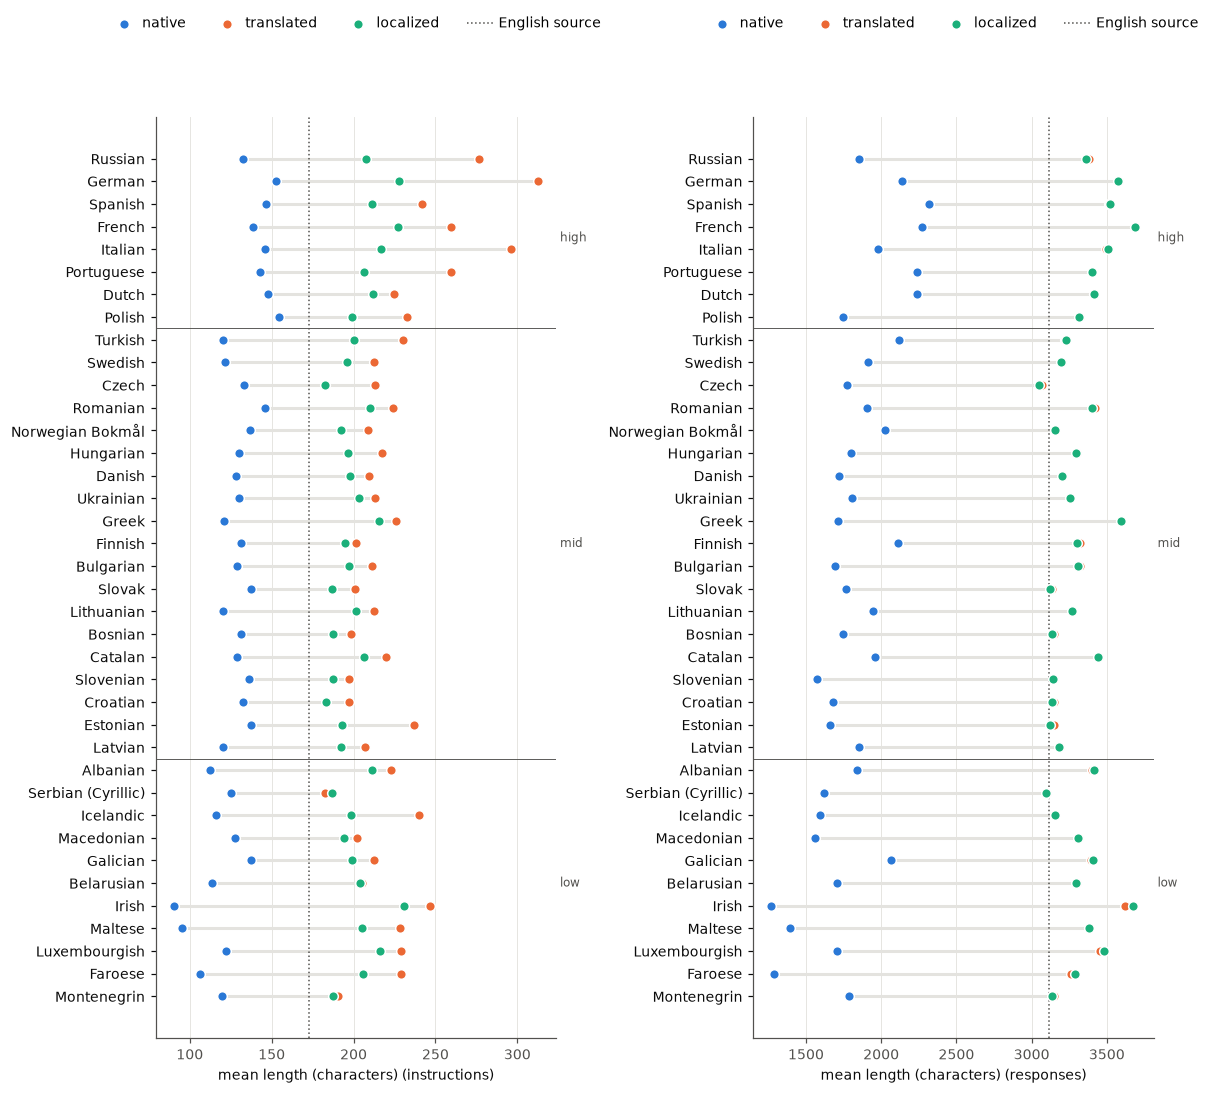

In [6]:
display(summary("chars_mean", "instruction"), summary("chars_mean", "response"))
fig, axes = plt.subplots(1, 2, figsize=(11, 0.22 * len(LANGS) + 1.6))
dotplot("chars_mean", "instruction", "mean length (characters)", axes[0])
dotplot("chars_mean", "response", "mean length (characters)", axes[1])
fig.tight_layout()
fig.savefig(OUT_DIR / "length_mean.pdf", bbox_inches="tight")

### Length distributions

Words per text (whitespace-split), per language and condition, on a log scale. Step lines are densities over
log-spaced bins; the dotted line is the English source. Responses at the far right end were cut off at the
generation limit (4096 tokens).

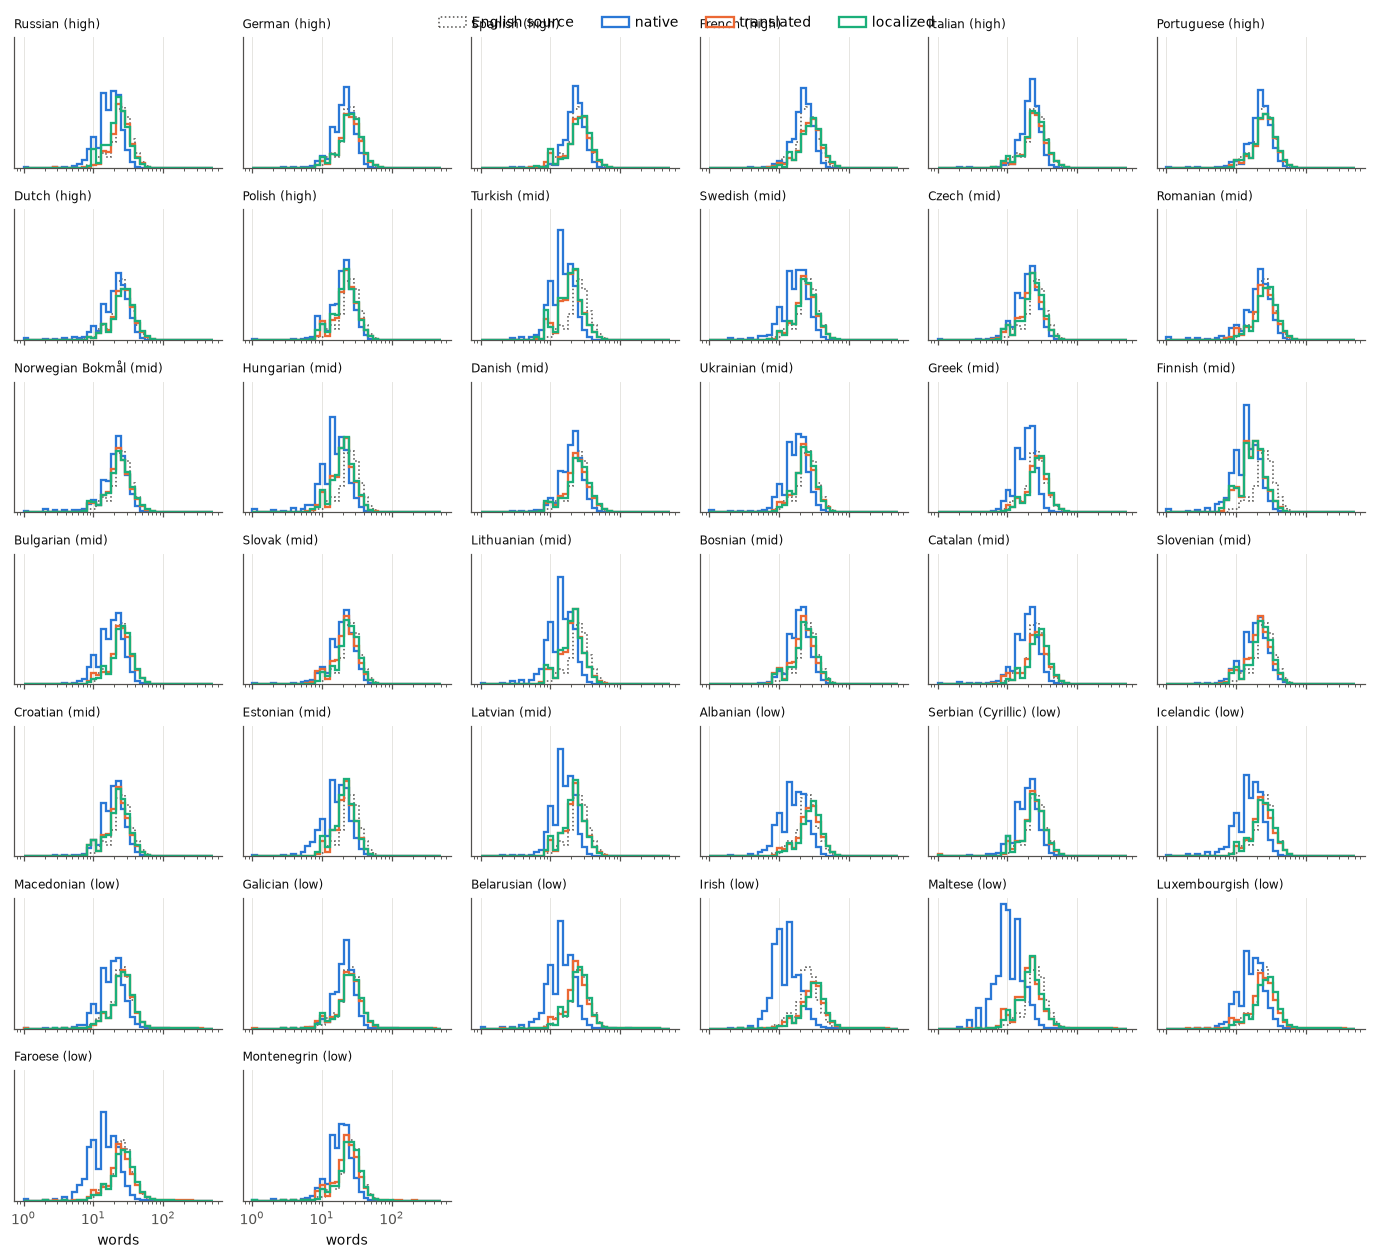

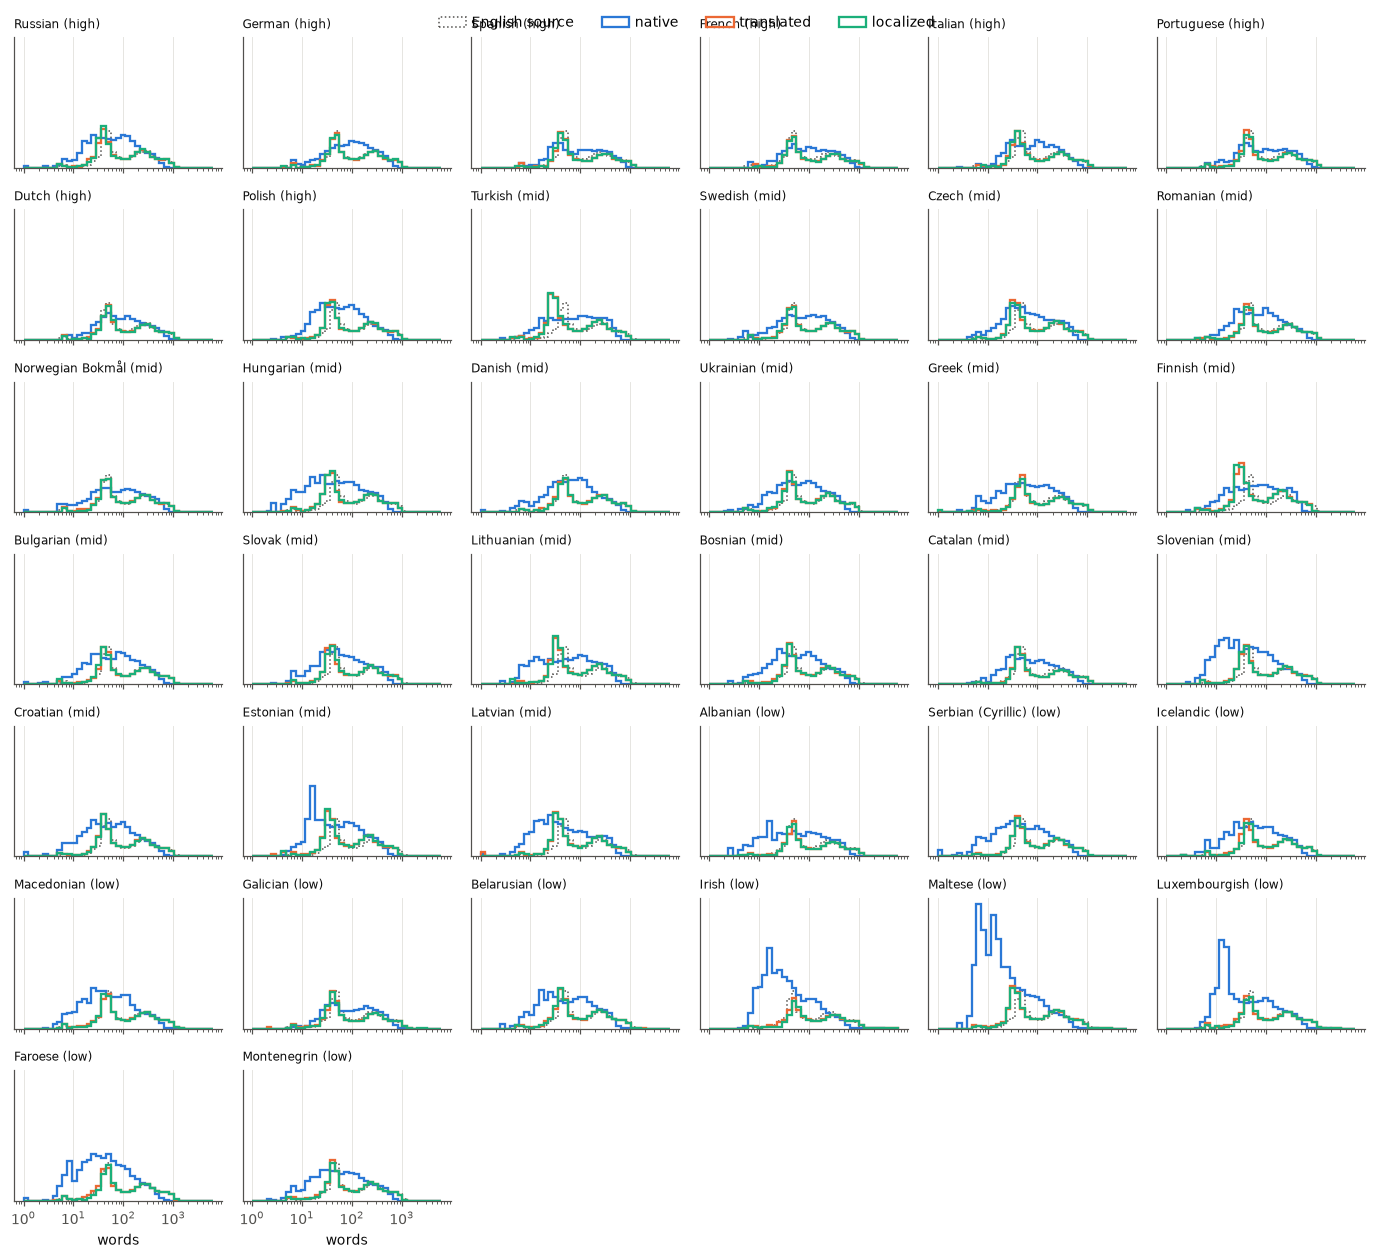

In [7]:
def length_grid(field, ncols=6):
    langs = [c for c in sorted(LANGS, key=lambda c: -RESOURCE.get(c, 0)) if any((k, c, field) in lengths for k in CONDITIONS)]
    nrows = math.ceil(len(langs) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.1 * ncols, 1.55 * nrows + 0.6), sharex=True, sharey=True, squeeze=False)
    hi = max(v.max() for (c, l, f), v in lengths.items() if f == field)
    bins = np.logspace(0, np.log10(hi + 1), 40)
    en = lengths.get(("english", "en", field))
    for ax, code in zip(axes.flat, langs):
        if en is not None:
            ax.hist(np.maximum(en, 1), bins=bins, density=True, histtype="step", color=INK_MUTED, linewidth=1,
                    linestyle=":", label="English source")
        for cond in CONDITIONS:
            if (cond, code, field) in lengths:
                ax.hist(np.maximum(lengths[(cond, code, field)], 1), bins=bins, density=True, histtype="step",
                        color=COLORS[cond], linewidth=1.5, label=cond)
        ax.set_xscale("log")
        ax.set_title(f"{LANGS[code]} ({TIER[code]})", loc="left", fontsize=8, color=INK)
        ax.grid(axis="y", visible=False)
        ax.set_yticks([])
    for ax in list(axes.flat)[len(langs):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("words")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0), handletextpad=0.4)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"length_distributions_{field}.pdf", bbox_inches="tight")
    return fig

length_grid("instruction")
length_grid("response");

p10  median    p90     p99
field       tier             condition                              
instruction (English source) english     19.0    28.0   43.0    60.0
            high             localized   19.0    29.0   46.0   135.0
                             native      16.0    24.0   34.0    46.0
                             translated  19.0    29.0   51.0   279.0
            low              localized   19.0    29.0   46.0   110.0
                             native      11.0    19.0   29.0    42.0
                             translated  18.0    28.0   47.0   179.0
            mid              localized   17.0    26.0   42.0    99.0
                             native      13.0    21.0   31.0    44.0
                             translated  17.0    26.0   43.0   199.0
response    (English source) english     71.0   395.0  897.0  1142.0
            high             localized   72.0   418.0  948.0  1213.0
                             native      64.0   266.0  591.0   813.0
                             translated  72.0   417.0  946.0  1209.0
            low              localized   73.0   404.0  913.0  1331.0
                             native      41.0   202.0  487.0   688.0
                             translated  71.0   402.0  908.0  1326.0
            mid              localized   66.0   373.0  853.0  1092.0
                             native      50.0   224.0  498.0   678.0
                             translated  65.0   373.0  854.0  1093.0

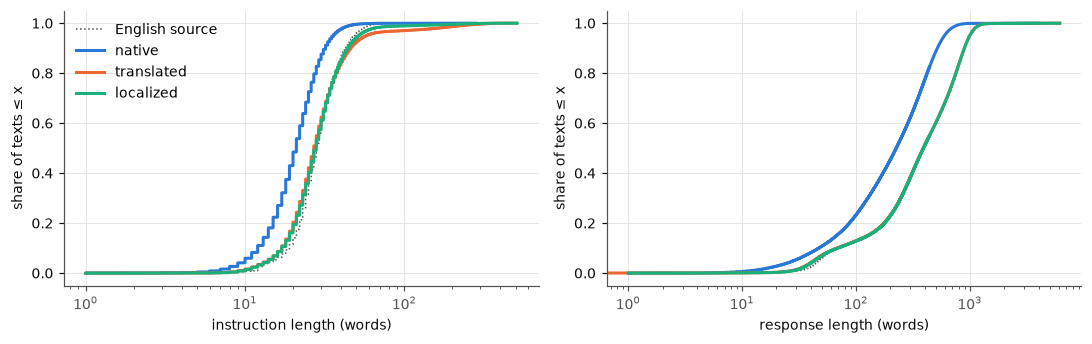

In [8]:
# Pooled over all languages: cumulative distribution per condition
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, field in zip(axes, FIELDS):
    en = lengths.get(("english", "en", field))
    if en is not None:
        x = np.sort(en)
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=INK_MUTED, linewidth=1, linestyle=":", label="English source")
    for cond in CONDITIONS:
        pooled = [v for (c, l, f), v in lengths.items() if c == cond and f == field]
        if pooled:
            x = np.sort(np.concatenate(pooled))
            ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=COLORS[cond], linewidth=2, label=cond)
    ax.set_xscale("log")
    ax.set_xlabel(f"{field} length (words)")
    ax.set_ylabel("share of texts ≤ x")
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "length_cdf_pooled.pdf", bbox_inches="tight")

# Quantiles per tier and condition
q = pd.DataFrame([{"tier": TIER.get(l, "-") if c != "english" else "(English source)", "condition": c, "field": f,
                   "p10": np.percentile(v, 10), "median": np.median(v), "p90": np.percentile(v, 90),
                   "p99": np.percentile(v, 99)} for (c, l, f), v in lengths.items()])
display(q.groupby(["field", "tier", "condition"])[["p10", "median", "p90", "p99"]].mean().round(0))

## 2. Lexical diversity

In [9]:
for field in FIELDS:
    print(f"== {field}s ==")
    display(pd.concat({m: summary(m, field) for m in ["ttr", "distinct2", "entropy", "compression"]}, axis=1))

== instructions ==


ttr                      distinct2                       entropy                      compression                     
condition         native translated localized    native translated localized   native translated localized      native translated localized
tier                                                                                                                                       
high              0.1083     0.1299    0.1122    0.4257     0.4754    0.4186   9.5080    10.1278    9.7380      3.0646     3.0077    3.1933
mid               0.1576     0.1438    0.1339    0.5398     0.4771    0.4511  10.1567    10.2224   10.0239      2.8253     3.0871    3.1676
low               0.1704     0.1278    0.1179    0.5534     0.4432    0.4158  10.0603     9.8343    9.6209      2.8267     3.2613    3.3399
(English source)  0.0678     0.0678    0.0678    0.3344     0.3344    0.3344   8.8775     8.8775    8.8775      3.1956     3.1956    3.1956

== responses ==


ttr                      distinct2                       entropy                      compression                     
condition         native translated localized    native translated localized   native translated localized      native translated localized
tier                                                                                                                                       
high              0.0554     0.0559    0.0553    0.4117     0.4326    0.4310  11.2532    11.4411   11.4062      2.9296     2.8875    2.8954
mid               0.0750     0.0759    0.0754    0.4885     0.5106    0.5089  11.9308    12.1621   12.1210      2.9231     2.8635    2.8791
low               0.0700     0.0670    0.0657    0.4371     0.4600    0.4527  11.3271    11.5969   11.4968      3.0698     3.0386    3.0673
(English source)  0.0313     0.0313    0.0313    0.4015     0.4015    0.4015  10.9006    10.9006   10.9006      2.6638     2.6638    2.6638

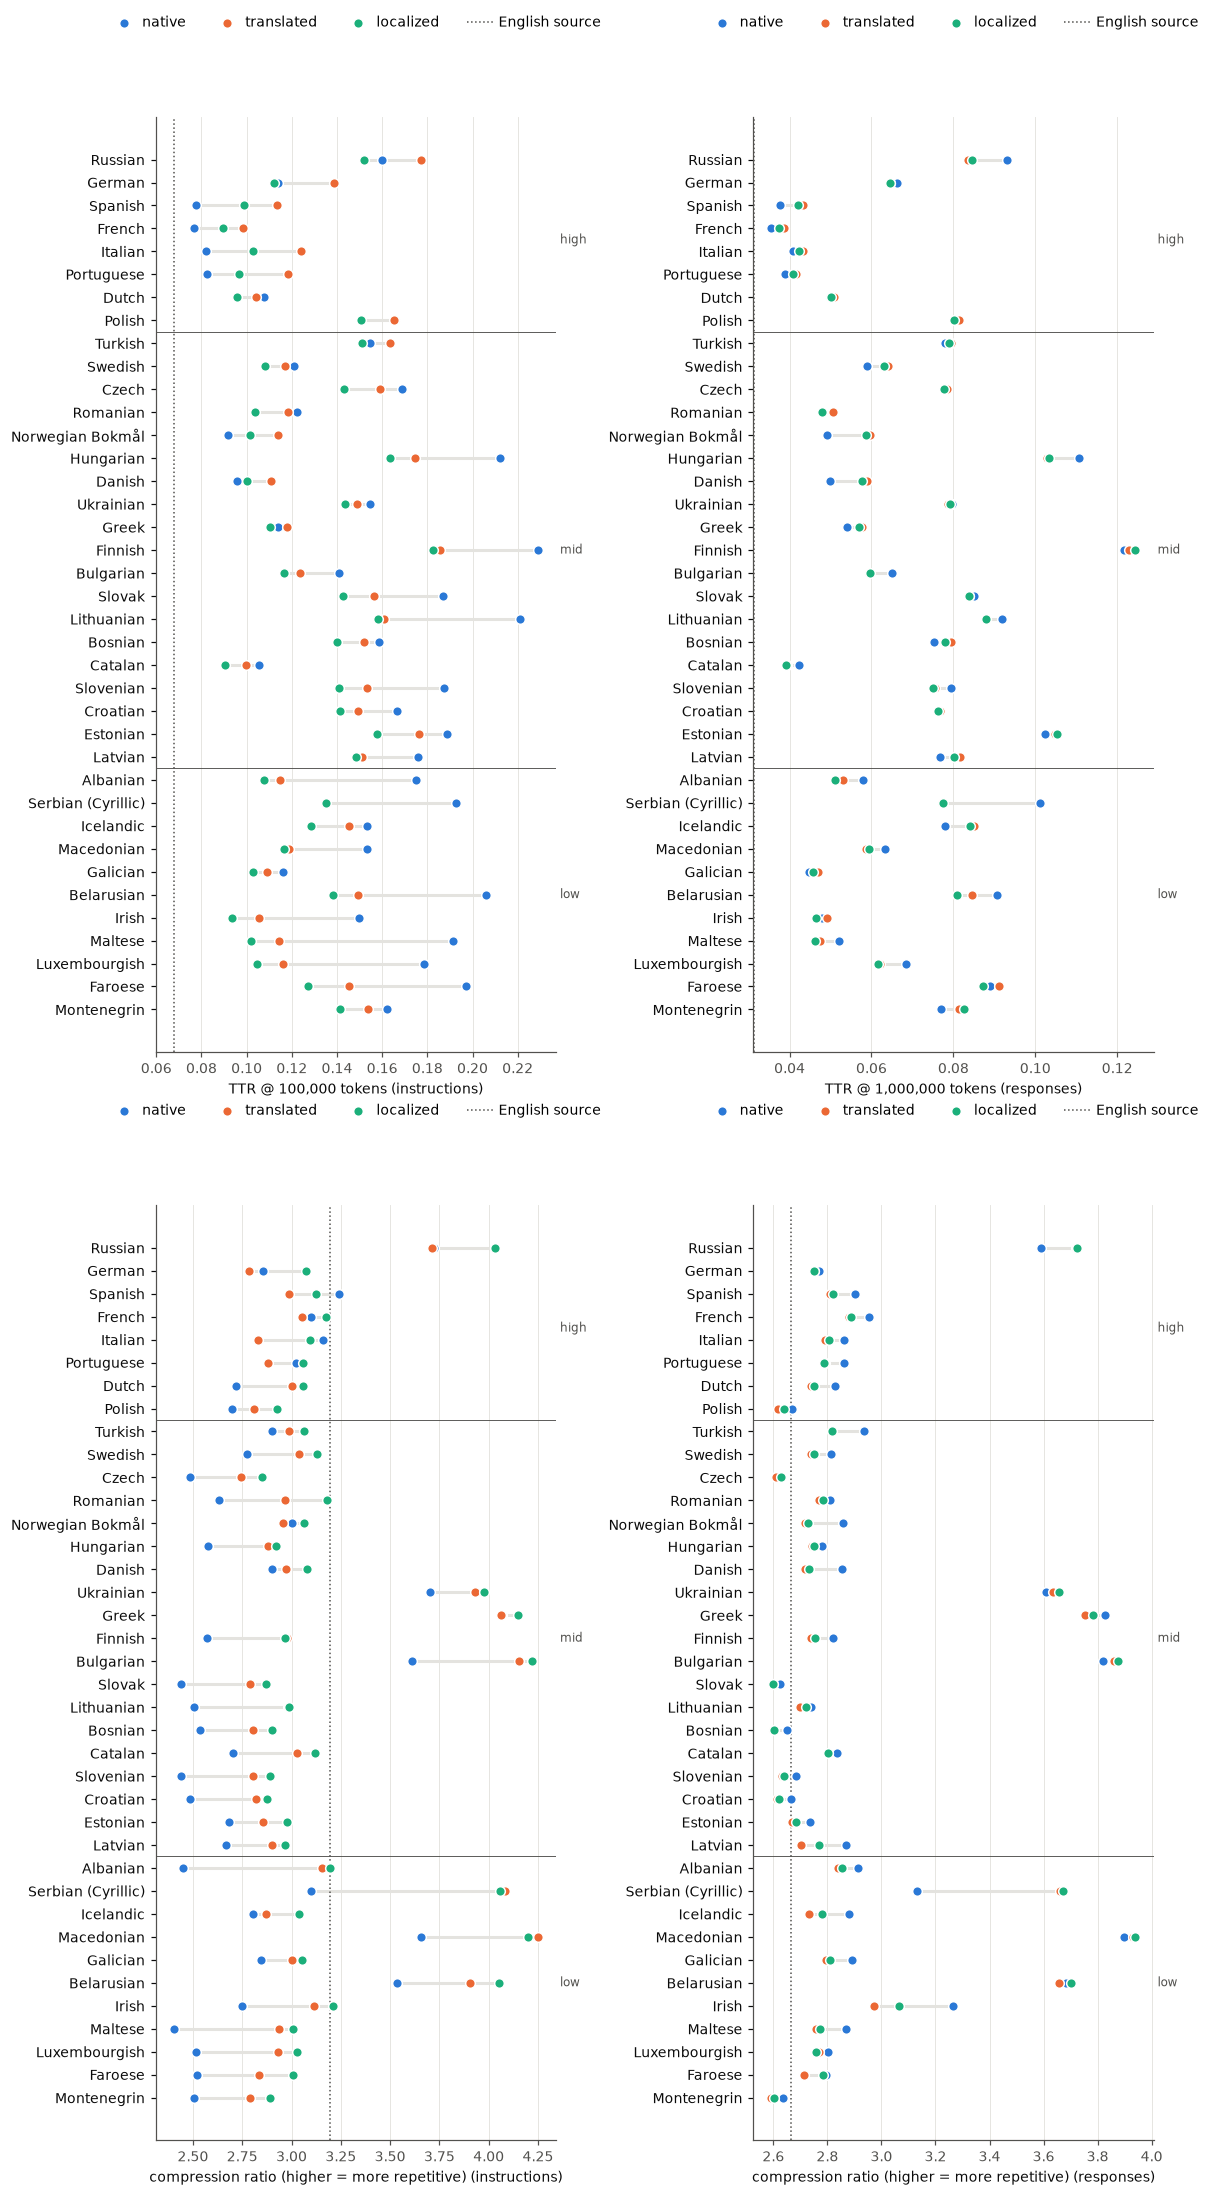

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 2 * (0.22 * len(LANGS) + 1.6)))
dotplot("ttr", "instruction", f"TTR @ {TOKEN_BUDGET['instruction']:,} tokens", axes[0, 0])
dotplot("ttr", "response", f"TTR @ {TOKEN_BUDGET['response']:,} tokens", axes[0, 1])
dotplot("compression", "instruction", "compression ratio (higher = more repetitive)", axes[1, 0])
dotplot("compression", "response", "compression ratio (higher = more repetitive)", axes[1, 1])
fig.tight_layout()
fig.savefig(OUT_DIR / "lexical_diversity.pdf", bbox_inches="tight")

## 3. Instruction homogeneity

Magpie-style generation tends to produce templated openings ("Can you help me…"). A higher top-10 share means
instructions start in fewer ways.

condition,native,translated,localized
tier,,,
high,0.3181,0.6909,0.6812
mid,0.1945,0.6915,0.6813
low,0.1551,0.7319,0.6911
(English source),0.8390,0.8390,0.8390


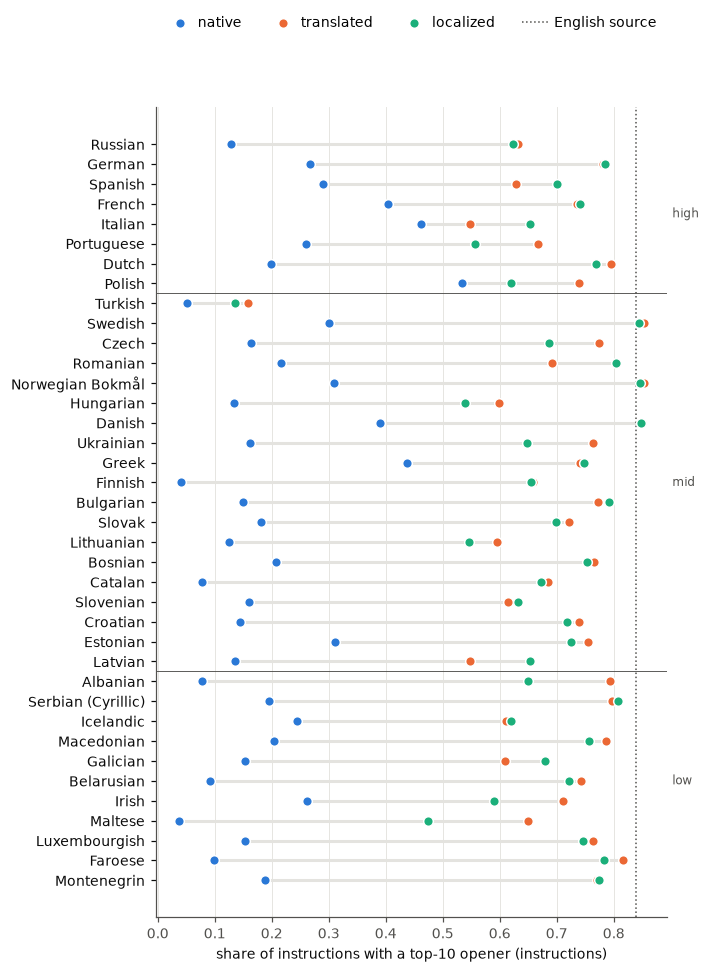

In [11]:
display(summary("opener_top10", "instruction"))
dotplot("opener_top10", "instruction", "share of instructions with a top-10 opener")
plt.show()

In [12]:
# Most frequent openers for one language, per condition
LANG = "da"
for cond in ["english", *CONDITIONS]:
    key = (cond, "en" if cond == "english" else LANG)
    if key in openers:
        print(f"{cond:>11}: " + " | ".join(f"{o} ({c})" for o, c in openers[key][:6]))

    english: hey can you (9678) | hey could you (3014) | okay so i (2497) | hey quick question (760) | okay so if (249) | hey can u (152)
     native: hey kan du (2988) | hej kan du (2067) | hvad er den (1209) | hvad er forskellen (341) | hvad er det (248) | bare lige hjælp (226)
 translated: hej kan du (10569) | okay så jeg (2672) | hej kunne du (2223) | hej hurtigt spørgsmål (839) | okay så hvis (247) | hej hurtigt kan (110)
  localized: hej kan du (10100) | hej kunne du (2696) | okay så jeg (2640) | hej hurtigt spørgsmål (789) | okay så hvis (212) | hey kan du (138)


## 4. Formatting conventions in responses

Share of responses using each markdown/style element. Translated responses inherit the English formatting,
so differences between native and translated show whether native generation follows other conventions.

In [13]:
fmt_cols = [f"fmt_{k}" for k in FORMAT_PATTERNS]
fmt = stats[stats.field == "response"].groupby(["condition"])[fmt_cols].mean()
fmt.columns = [c[4:] for c in fmt_cols]
display(fmt.round(3))
display(wide("fmt_bullets", "response").round(3))   # per language, for one element

,header,bullets,numbered,bold,code_block,table,emoji
condition,,,,,,,
english,0.066,0.828,0.115,0.892,0.017,0.008,0.078
localized,0.066,0.827,0.115,0.891,0.017,0.008,0.079
native,0.022,0.773,0.166,0.846,0.015,0.012,0.079
translated,0.066,0.827,0.115,0.890,0.016,0.008,0.077


condition,tier,native,translated,localized
lang,,,,
ru,high,0.793,0.827,0.828
de,high,0.820,0.827,0.827
es,high,0.811,0.827,0.827
fr,high,0.822,0.827,0.827
it,high,0.768,0.827,0.828
pt,high,0.830,0.827,0.828
nl,high,0.824,0.827,0.827
pl,high,0.771,0.827,0.828
tr,mid,0.820,0.827,0.828


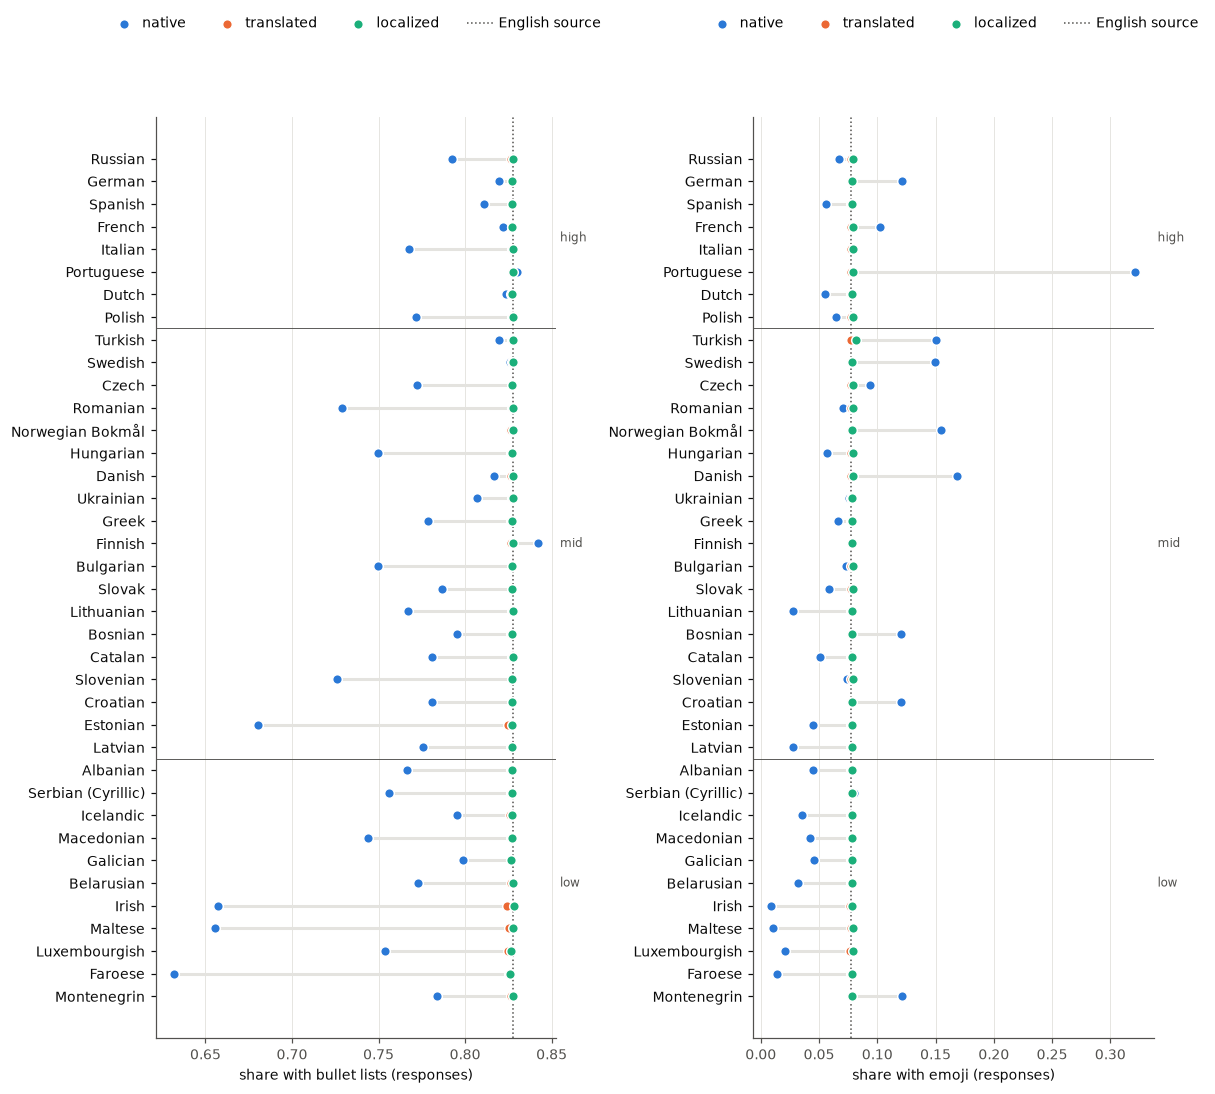

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 0.22 * len(LANGS) + 1.6))
dotplot("fmt_bullets", "response", "share with bullet lists", axes[0])
dotplot("fmt_emoji", "response", "share with emoji", axes[1])
fig.tight_layout()
fig.savefig(OUT_DIR / "formatting.pdf", bbox_inches="tight")

## 5. Translation checks

- **len_ratio_to_en**: median character-length ratio of translated responses to their English source (matched by `id`).
  Values far below the language's typical expansion suggest omissions.
- **truncated_share**: share of rows where the translation hit the token limit.

In [15]:
checks = stats[(stats.field == "response") & stats.condition.isin(["translated", "localized"])]
cols = [c for c in ["len_ratio_to_en", "truncated_share"] if c in checks]
display(checks.pivot(index="lang", columns="condition", values=cols).round(3))

len_ratio_to_en            truncated_share           
condition       localized translated       localized translated
lang                                                           
be                  1.055      1.058           0.004      0.005
bg                  1.057      1.062           0.003      0.006
bs                  1.004      1.006           0.003      0.006
ca                  1.104      1.106           0.002      0.006
cnr                 1.002      1.007           0.002      0.004
cs                  0.973      0.981           0.003      0.007
da                  1.033      1.032           0.003      0.006
de                  1.154      1.158           0.003      0.018
el                  1.154      1.157           0.005      0.008
es                  1.128      1.127           0.003      0.008
et                  0.999      1.001           0.004      0.014
fi                  1.060      1.065           0.003      0.005
fo                  1.027      1.021           0.011      0.018
fr                  1.182      1.185           0.003      0.007
ga                  1.129      1.113           0.022      0.029
gl                  1.085      1.085           0.003      0.004
hr                  1.001      1.005           0.003      0.006
hu                  1.055      1.058           0.003      0.011
is                  1.013      1.007           0.007      0.020
it                  1.124      1.121           0.004      0.019
lb                  1.105      1.097           0.008      0.014
lt                  1.040      1.038           0.004      0.008
lv                  1.014      1.014           0.005      0.009
mk                  1.057      1.061           0.004      0.004
mt                  1.080      1.075           0.008      0.019
nb                  1.015      1.016           0.003      0.006
nl                  1.101      1.101           0.003      0.006
pl                  1.062      1.064           0.004      0.010
pt                  1.089      1.090           0.003      0.012
ro                  1.091      1.099           0.003      0.008
ru                  1.074      1.084           0.003      0.014
sk                  0.998      1.000           0.003      0.007
sl                  1.005      1.008           0.003      0.006
sq                  1.094      1.095           0.006      0.012
sr                  0.987      0.991           0.003      0.003
sv                  1.029      1.032           0.002      0.006
tr                  1.034      1.034           0.004      0.009
uk                  1.043      1.042           0.004      0.006

## 6. Semantic diversity and distance to the English source *(optional, GPU)*

Embeds `KEEP_SAMPLE` instructions per set with a multilingual encoder and reports:
- **mean pairwise cosine**: average similarity between instructions in a set (*higher = more homogeneous*);
- **Vendi score**: effective number of distinct instructions (Friedman & Dieng, 2023), computed on the cosine kernel;
- **centroid distance to English**: cosine distance between the set's mean embedding and the English source's.
  Translated sets carry the same content as the English source, so their distance is mostly the language offset
  of the encoder; how much further the native set is gives an estimate of the *content* shift of native generation.

In [16]:
def semantic_metrics(emb):
    sims = emb @ emb.T
    n = len(emb)
    mean_cos = float((sims.sum() - n) / (n * (n - 1)))
    eig = np.clip(np.linalg.eigvalsh(sims / n), 0, None)
    eig = eig[eig > 0]
    vendi = float(np.exp(-(eig * np.log(eig)).sum()))
    return mean_cos, vendi

def centroid_distance(a, b):
    ca, cb = a.mean(0), b.mean(0)
    return float(1 - ca @ cb / (np.linalg.norm(ca) * np.linalg.norm(cb)))

if RUN_EMBEDDINGS:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer(EMBED_MODEL, device="cuda")
    encoder.half()
    encoder.max_seq_length = 256
    embs = {key: encoder.encode(s["instruction"].tolist(), batch_size=256, normalize_embeddings=True,
                                convert_to_numpy=True).astype(np.float32)
            for key, s in samples.items()}
    sem_rows = []
    for (cond, code), emb in embs.items():
        mean_cos, vendi = semantic_metrics(emb)
        row = {"lang": code, "condition": cond, "mean_cos": mean_cos, "vendi": vendi}
        if ("english", "en") in embs:
            row["dist_to_en"] = centroid_distance(emb, embs[("english", "en")])
        sem_rows.append(row)
    sem = pd.DataFrame(sem_rows)
    sem.to_csv(OUT_DIR / "semantic_per_set.csv", index=False)
    display(sem.pivot(index="lang", columns="condition", values=["mean_cos", "vendi", "dist_to_en"]).round(3))
else:
    print("Skipped (RUN_EMBEDDINGS = False).")

Skipped (RUN_EMBEDDINGS = False).


## 7. Native − translated differences vs. resourcedness

For each language: native value minus translated value (and localized minus translated), so that morphology and
script effects cancel out. Positive for TTR/distinct-n means native is *more* diverse; positive for compression
and opener share means native is *more* repetitive. The x-axis is the language's FineWeb-2 size (log10 words, see `RESOURCE`),
and the Spearman correlation with the size is printed for each panel.

ttr/instruction native−translated vs FineWeb-2 size: Spearman ρ = -0.83
ttr/instruction localized−translated vs FineWeb-2 size: Spearman ρ = -0.34
ttr/response native−translated vs FineWeb-2 size: Spearman ρ = -0.23
ttr/response localized−translated vs FineWeb-2 size: Spearman ρ = 0.19
compression/response native−translated vs FineWeb-2 size: Spearman ρ = -0.10
compression/response localized−translated vs FineWeb-2 size: Spearman ρ = -0.34
opener_top10/instruction native−translated vs FineWeb-2 size: Spearman ρ = 0.43
opener_top10/instruction localized−translated vs FineWeb-2 size: Spearman ρ = 0.19


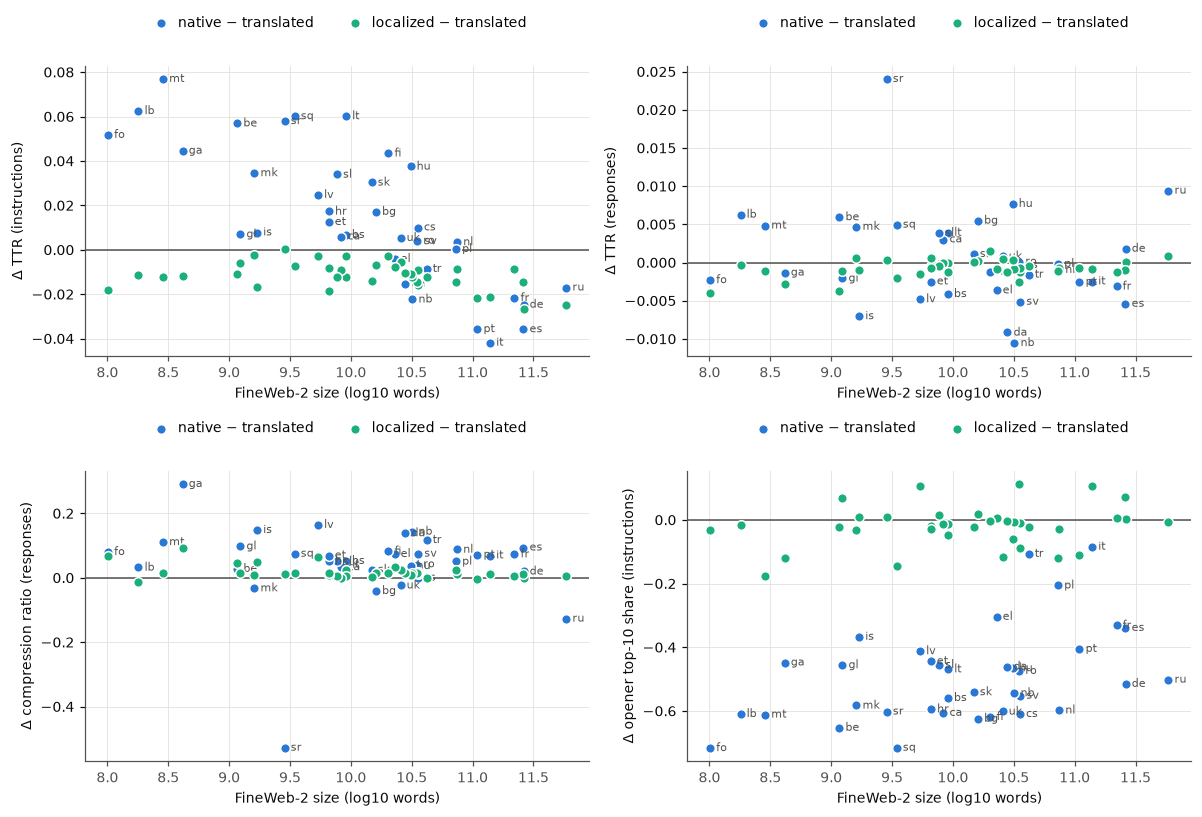

In [17]:
def deltas(metric, field, data=None):
    t = wide(metric, field, data)
    out = pd.DataFrame({"tier": t["tier"]})
    if {"native", "translated"} <= set(t.columns):
        out["native"] = t["native"] - t["translated"]
    if {"localized", "translated"} <= set(t.columns):
        out["localized"] = t["localized"] - t["translated"]
    return out

def delta_plot(metric, field, label, ax=None, data=None):
    d = deltas(metric, field, data)
    d = d[d.index.isin(RESOURCE)]   # languages without a FineWeb-2 size (Montenegrin) cannot be placed
    ax = ax or plt.subplots(figsize=(6, 3.4))[1]
    use_resource = RESOURCE and all(c in RESOURCE for c in d.index)
    for k, cond in enumerate([c for c in ["native", "localized"] if c in d]):
        if use_resource:
            x = np.log10([RESOURCE[c] for c in d.index])
        else:
            jitter = np.random.default_rng(k).uniform(-0.12, 0.12, len(d))
            x = np.array([TIER_ORDER.index(t) for t in d["tier"]]) + (k - 0.5) * 0.3 + jitter
        ax.scatter(x, d[cond], s=40, color=COLORS[cond], edgecolor="white", linewidth=1, zorder=3,
                   label=f"{cond} − translated")
        if cond == "native":
            for xi, yi, c in zip(x, d[cond], d.index):
                ax.annotate(c, (xi, yi), xytext=(4, 0), textcoords="offset points", fontsize=7,
                            color=INK_MUTED, va="center")
        if use_resource:
            r = pd.Series(x).rank().corr(d[cond].reset_index(drop=True).rank())   # Spearman, no scipy needed
            print(f"{metric}/{field} {cond}−translated vs FineWeb-2 size: Spearman ρ = {r:.2f}")
    ax.axhline(0, color=INK_MUTED, linewidth=1)
    if not use_resource:
        ax.set_xticks(range(len(TIER_ORDER)), TIER_ORDER)
        ax.grid(axis="x", visible=False)
        ax.set_xlabel("resource tier")
    else:
        ax.set_xlabel("FineWeb-2 size (log10 words)")
    ax.set_ylabel(f"{label} ({field}s)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=2, handletextpad=0.2)
    return ax

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
delta_plot("ttr", "instruction", "Δ TTR", axes[0, 0])
delta_plot("ttr", "response", "Δ TTR", axes[0, 1])
delta_plot("compression", "response", "Δ compression ratio", axes[1, 0])
delta_plot("opener_top10", "instruction", "Δ opener top-10 share", axes[1, 1])
fig.tight_layout()
fig.savefig(OUT_DIR / "deltas_vs_resource.pdf", bbox_inches="tight")

In [18]:
# Mean difference per tier for the main metrics
tbl = pd.concat({f"{m}/{f}": deltas(m, f).groupby("tier").mean().reindex(TIER_ORDER)
                 for m, f in [("ttr", "instruction"), ("ttr", "response"), ("distinct2", "response"),
                              ("compression", "response"), ("opener_top10", "instruction")]}, axis=1)
display(tbl.round(4))

ttr/instruction           ttr/response           distinct2/response           compression/response           opener_top10/instruction          
              native localized       native localized             native localized               native localized                   native localized
tier                                                                                                                                                
high         -0.0216   -0.0177      -0.0004   -0.0006            -0.0209   -0.0016               0.0421    0.0079                  -0.3728   -0.0097
mid           0.0138   -0.0099      -0.0009   -0.0004            -0.0221   -0.0017               0.0596    0.0155                  -0.4970   -0.0102
low           0.0426   -0.0100       0.0031   -0.0013            -0.0229   -0.0073               0.0312    0.0287                  -0.5769   -0.0409

## 8. Length-matched comparison

Native texts are much shorter than translated ones (section 1), so differences in diversity or formatting may
simply follow from length. Here, for each language and field, the three conditions are subsampled so that they
have the **same number of texts in every length bin** (word counts in ~10%-wide log-spaced bins; texts in bins
where one condition has fewer are dropped at random). This also removes most of the overlong translated
instructions (where the model answered instead of translating), as native has almost no texts of that length.

The diversity metrics are then recomputed on the matched subsets, with the token budget per language set to what
the smallest matched subset allows (capped at `TOKEN_BUDGET`), so all three conditions of a language are measured
on the same amount of text.

In [19]:
MATCH_BINS = np.unique(np.round(np.logspace(0, 4.2, 100)).astype(int))   # word-count bin edges, ~10% wide

def match_lengths(texts_by_cond, seed=SEED):
    '''Subsample each condition so that all have the same number of texts in every length bin.'''
    rng = np.random.default_rng(seed)
    bins = {c: np.digitize([len(t.split()) for t in ts], MATCH_BINS) for c, ts in texts_by_cond.items()}
    keep = {c: [] for c in texts_by_cond}
    for b in np.unique(np.concatenate(list(bins.values()))):
        idx = {c: np.flatnonzero(bins[c] == b) for c in texts_by_cond}
        k = min(len(i) for i in idx.values())
        for c, i in idx.items():
            keep[c].extend(rng.choice(i, k, replace=False).tolist())
    return {c: [texts_by_cond[c][i] for i in sorted(keep[c])] for c in texts_by_cond}

matched_rows = []
for code in LANGS:
    print(code, end=" ", flush=True)
    dfs = {cond: load(repo, code) for cond, repo in CONDITIONS.items()}
    dfs = {cond: df for cond, df in dfs.items() if df is not None}
    if len(dfs) < 2:
        continue
    for field in FIELDS:
        texts = match_lengths({cond: df[field].fillna("").tolist() for cond, df in dfs.items()})
        n_tokens = min(sum(len(TOKEN_RE.findall(t)) for t in ts) for ts in texts.values())
        n_chars = min(sum(len(t) + 1 for t in ts) for ts in texts.values())
        token_budget = min(TOKEN_BUDGET[field], n_tokens)
        char_budget = min(CHAR_BUDGET[field], n_chars)
        for cond, ts in texts.items():
            row = {"lang": code, "tier": TIER.get(code), "condition": cond, "field": field, "n": len(ts),
                   "kept_share": len(ts) / len(dfs[cond]), "token_budget": token_budget,
                   "words_median": float(np.median([len(t.split()) for t in ts])),
                   "chars_mean": float(np.mean([len(t) for t in ts]))}
            order = np.random.default_rng(SEED).permutation(len(ts))
            row.update(lexical_metrics(ts, field, order, token_budget, char_budget))
            if field == "instruction":
                row["opener_top10"] = opener_share(ts)[0]
            else:
                row.update({f"fmt_{k}": v for k, v in format_shares(ts).items()})
            matched_rows.append(row)
print()

matched = pd.DataFrame(matched_rows)
matched.to_csv(OUT_DIR / "stats_length_matched.csv", index=False)

# How much is left after matching, and does the matching hold?
display(matched.pivot_table(index=["field", "tier"], columns="condition",
                            values=["n", "kept_share", "words_median"], aggfunc="mean").round(2))
display(matched.groupby("field")["token_budget"].describe()[["min", "50%", "max"]])

de fr es it pt ru pl nl sv da nb cs ro uk hu fi bg ca hr sk sr sl et be mk gl is fo lb tr el lt bs lv sq ga mt cnr 


kept_share                           n                      words_median                   
condition         localized native translated localized    native translated    localized  native translated
field       tier                                                                                            
instruction high       0.70   0.70       0.70  14008.25  14008.25   14008.25        26.12   26.12      26.12
            low        0.51   0.51       0.51  10173.73  10173.73   10173.73        23.73   23.73      23.73
            mid        0.69   0.69       0.69  13766.74  13766.74   13766.74        23.42   23.42      23.42
response    high       0.71   0.71       0.71  14218.12  14218.12   14218.12       320.81  320.75     320.75
            low        0.64   0.64       0.64  12897.64  12897.64   12897.64       284.18  284.09     284.14
            mid        0.68   0.68       0.68  13670.95  13670.95   13670.95       277.63  277.37     277.42

,min,50%,max
field,,,
instruction,100000.0,100000.0,100000.0
response,1000000.0,1000000.0,1000000.0


In [20]:
# Native − translated, per tier: all data vs. length-matched
METRICS = [("ttr", "instruction"), ("distinct2", "instruction"), ("opener_top10", "instruction"),
           ("ttr", "response"), ("distinct2", "response"), ("entropy", "response"), ("compression", "response")]

def native_delta_by_tier(metric, field, data=None):
    d = deltas(metric, field, data)
    return d["native"].groupby(d["tier"]).mean()

cmp = pd.concat({f"{m}/{f}": pd.concat({"all": native_delta_by_tier(m, f),
                                         "matched": native_delta_by_tier(m, f, matched)}, axis=1).reindex(TIER_ORDER)
                 for m, f in METRICS}, axis=1)
display(cmp.round(4))

for field in FIELDS:
    print(f"== {field}s, length-matched ==")
    display(pd.concat({m: summary(m, field, matched) for m in ["ttr", "distinct2", "entropy", "compression"]}, axis=1))

ttr/instruction         distinct2/instruction         opener_top10/instruction         ttr/response         distinct2/response         entropy/response         compression/response        
                 all matched                   all matched                      all matched          all matched                all matched              all matched                  all matched
tier                                                                                                                                                                                             
high         -0.0216  0.0085               -0.0497  0.0654                  -0.3728 -0.4015      -0.0004  0.0019            -0.0209 -0.0045          -0.1879 -0.0566               0.0421  0.0741
mid           0.0138  0.0329                0.0626  0.1357                  -0.4970 -0.5262      -0.0009  0.0024            -0.0221 -0.0013          -0.2313 -0.0540               0.0596  0.0946
low           0.0426  0.0528                0.1102  0.1749                  -0.5769 -0.5998       0.0031  0.0060            -0.0229  0.0003          -0.2699 -0.0687               0.0312  0.0906

== instructions, length-matched ==


ttr                      distinct2                       entropy                      compression                     
condition  native translated localized    native translated localized   native translated localized      native translated localized
tier                                                                                                                                
high       0.1068     0.0983    0.0993    0.4263     0.3609    0.3634   9.4857     9.3593    9.3706      3.0655     3.4521    3.4735
mid        0.1542     0.1213    0.1213    0.5384     0.4027    0.3999  10.1183     9.7006    9.6695      2.8378     3.3693    3.4022
low        0.1640     0.1112    0.1093    0.5470     0.3721    0.3648   9.9799     9.3869    9.3373      2.8454     3.5712    3.6081

== responses, length-matched ==


ttr                      distinct2                       entropy                      compression                     
condition  native translated localized    native translated localized   native translated localized      native translated localized
tier                                                                                                                                
high       0.0552     0.0533    0.0532    0.4123     0.4168    0.4160  11.2586    11.3152   11.2926      2.9436     2.8695    2.8738
mid        0.0749     0.0725    0.0723    0.4898     0.4911    0.4909  11.9436    11.9976   11.9804      2.9392     2.8446    2.8529
low        0.0698     0.0638    0.0631    0.4399     0.4397    0.4352  11.3506    11.4192   11.3601      3.0886     2.9979    3.0121

ttr/instruction native−translated vs FineWeb-2 size: Spearman ρ = -0.68
ttr/instruction localized−translated vs FineWeb-2 size: Spearman ρ = 0.29
ttr/response native−translated vs FineWeb-2 size: Spearman ρ = -0.25
ttr/response localized−translated vs FineWeb-2 size: Spearman ρ = 0.29
distinct2/response native−translated vs FineWeb-2 size: Spearman ρ = -0.07
distinct2/response localized−translated vs FineWeb-2 size: Spearman ρ = 0.23
opener_top10/instruction native−translated vs FineWeb-2 size: Spearman ρ = 0.44
opener_top10/instruction localized−translated vs FineWeb-2 size: Spearman ρ = 0.20


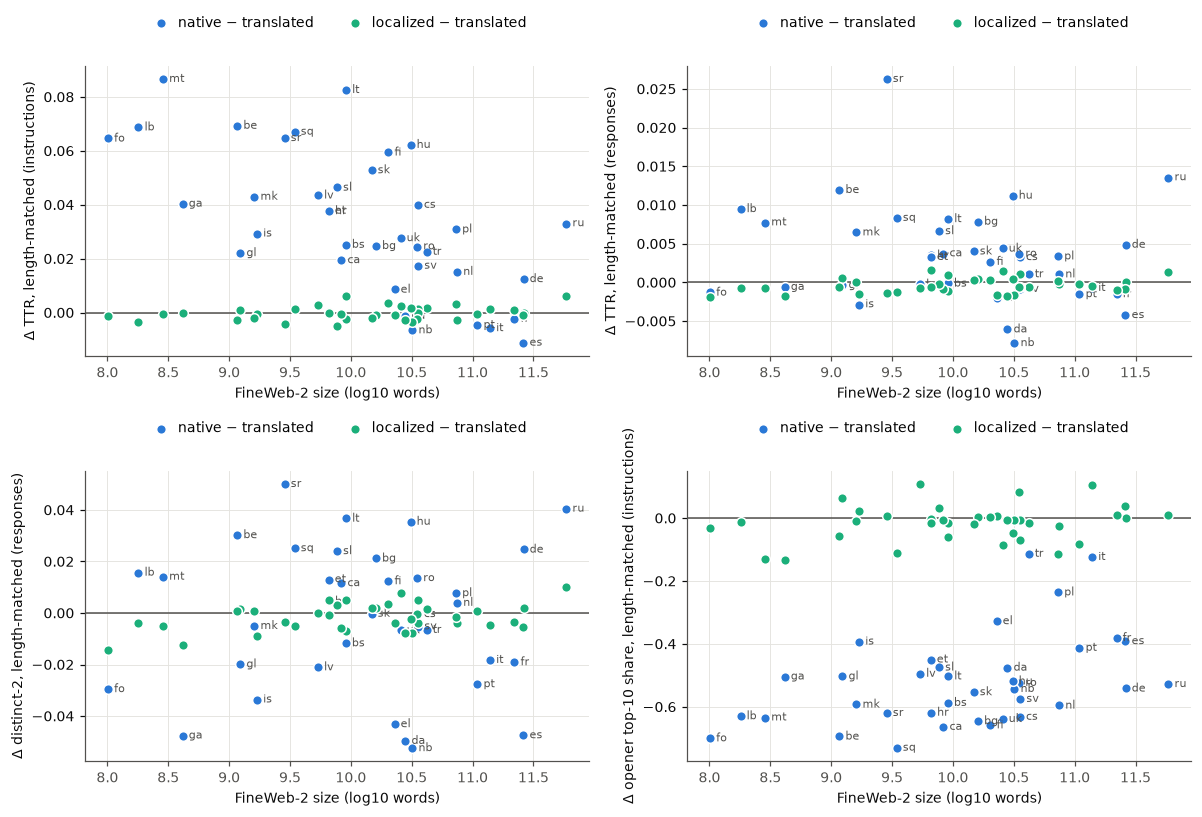

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
delta_plot("ttr", "instruction", "Δ TTR, length-matched", axes[0, 0], data=matched)
delta_plot("ttr", "response", "Δ TTR, length-matched", axes[0, 1], data=matched)
delta_plot("distinct2", "response", "Δ distinct-2, length-matched", axes[1, 0], data=matched)
delta_plot("opener_top10", "instruction", "Δ opener top-10 share, length-matched", axes[1, 1], data=matched)
fig.tight_layout()
fig.savefig(OUT_DIR / "deltas_vs_resource_length_matched.pdf", bbox_inches="tight")

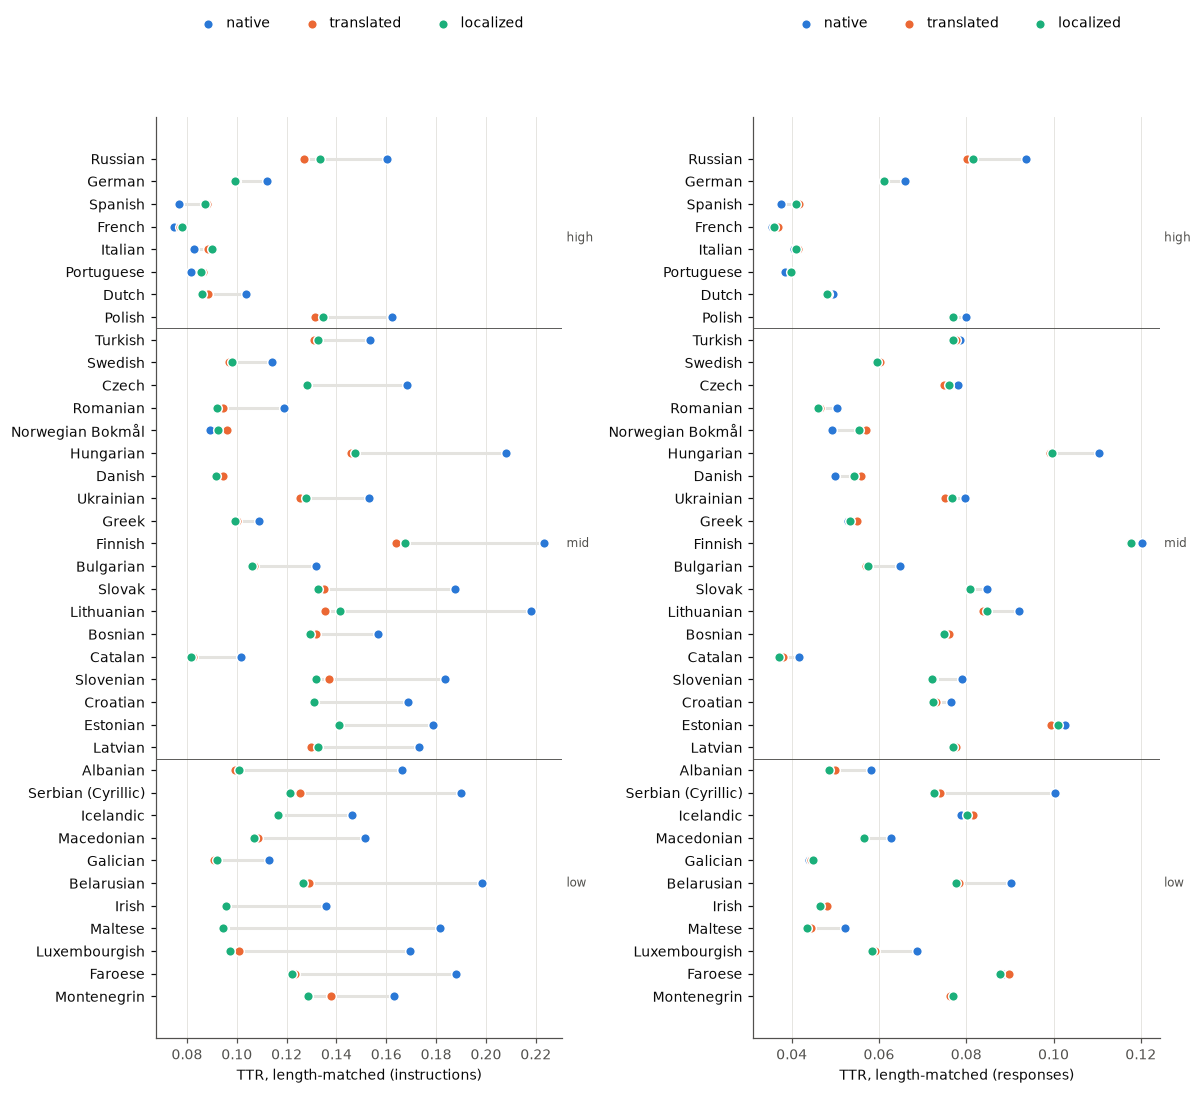

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 0.22 * len(LANGS) + 1.6))
dotplot("ttr", "instruction", "TTR, length-matched", axes[0], data=matched)
dotplot("ttr", "response", "TTR, length-matched", axes[1], data=matched)
fig.tight_layout()
fig.savefig(OUT_DIR / "ttr_length_matched.pdf", bbox_inches="tight")

In [23]:
# Formatting on length-matched responses: does native still use fewer headers / more numbered lists?
fmt_m = matched[matched.field == "response"].groupby("condition")[fmt_cols].mean()
fmt_m.columns = [c[4:] for c in fmt_cols]
display(pd.concat({"all": fmt.drop(index="english", errors="ignore"), "matched": fmt_m}, axis=0).round(3))

header  bullets  numbered   bold  code_block  table  emoji
        condition                                                             
all     localized    0.066    0.827     0.115  0.891       0.017  0.008  0.079
        native       0.022    0.773     0.166  0.846       0.015  0.012  0.079
        translated   0.066    0.827     0.115  0.890       0.016  0.008  0.077
matched localized    0.038    0.771     0.090  0.859       0.010  0.004  0.099
        native       0.027    0.825     0.194  0.886       0.019  0.014  0.072
        translated   0.037    0.772     0.090  0.859       0.010  0.004  0.096

## 9. Topics

Which topics does each set cover, and does native generation move away from the English topic mix, more so in
lower-resource languages?

- **Sample**: `TOPIC_N` native instructions per language; `TOPIC_N` English source instructions, and the *same*
  instructions (matched by `id`) in every translated and localized set.
- **Embedding**: bge-m3 (dense CLS embedding), via plain `transformers`.
- **Removing the language signal**: multilingual embeddings still cluster partly by language. Each language's
  embeddings are centered on the mean of its *translated* set (whose content is the English source's), English on
  its own mean. Language identity cancels out, while native keeps whatever content differs from the English source.
- **Topics**: spherical k-means with `N_TOPICS` clusters, fitted on native + translated; English and localized are
  assigned to the nearest centroid. Each topic is labelled with c-TF-IDF keywords of its English members and the
  native instructions closest to the centroid.
- **Sanity check**: a translated instruction should land in the same topic as its English source. The agreement
  rate per language shows how well the shared space works for that language.

Metrics per set: **effective number of topics** (exp of the topic entropy; lower = more concentrated) and
**Jensen–Shannon distance to the English source** topic distribution. The translated sets' distance is the noise
floor (same content, so only sampling noise and embedding error).

In [24]:
import torch
from transformers import AutoModel, AutoTokenizer

TOPIC_N = 2000
N_TOPICS = 40
TOPIC_CACHE = OUT_DIR / f"topic_embeddings_{TOPIC_N}.npz"

def pick_device():
    if torch.cuda.is_available():
        return "cuda"
    return "mps" if torch.backends.mps.is_available() else "cpu"

def embed_texts(texts, model, tok, device, batch=64, max_length=128):
    '''Normalized bge-m3 dense embeddings (CLS token); batches sorted by length for speed.'''
    order = np.argsort([len(t) for t in texts])
    out = []
    for s in range(0, len(texts), batch):
        idx = order[s:s + batch]
        enc = tok([texts[i] for i in idx], padding=True, truncation=True, max_length=max_length,
                  return_tensors="pt").to(device)
        with torch.no_grad():
            h = model(**enc).last_hidden_state[:, 0].float()
        out.append(torch.nn.functional.normalize(h, dim=-1).cpu().numpy())
    emb = np.empty((len(texts), out[0].shape[1]), dtype=np.float32)
    emb[order] = np.concatenate(out)
    return emb

# Sample: English source + the same ids in translated/localized; an independent sample of native
en_full = load(NATIVE_REPO, "en")
en_sample = en_full.iloc[np.random.default_rng(SEED).choice(len(en_full), TOPIC_N, replace=False)]
en_ids = set(en_sample["id"])
topic_texts = {("english", "en"): en_sample[["id", "instruction"]].reset_index(drop=True)}
for code in LANGS:
    for cond, repo in CONDITIONS.items():
        df = load(repo, code)
        if df is None:
            continue
        if cond == "native":
            sub = df.iloc[np.random.default_rng(SEED).choice(len(df), min(TOPIC_N, len(df)), replace=False)]
        else:
            sub = df[df["id"].isin(en_ids)]
        topic_texts[(cond, code)] = sub[["id", "instruction"]].reset_index(drop=True)

def load_encoder():
    device = pick_device()
    tok = AutoTokenizer.from_pretrained(EMBED_MODEL)
    model = AutoModel.from_pretrained(EMBED_MODEL, dtype=torch.float16 if device != "cpu" else torch.float32)
    return model.to(device).eval(), tok, device

# Embeddings are cached per set; only sets missing from the cache are embedded.
cache = dict(np.load(TOPIC_CACHE)) if TOPIC_CACHE.exists() else {}
topic_emb = {key: cache[f"{key[0]}|{key[1]}"] for key, df in topic_texts.items()
             if len(cache.get(f"{key[0]}|{key[1]}", [])) == len(df)}
todo = [key for key in topic_texts if key not in topic_emb]
print(f"{len(topic_emb)} sets loaded from {TOPIC_CACHE}, {len(todo)} to embed")
if todo:
    enc_model, tok, device = load_encoder()
    for k, key in enumerate(todo):
        topic_emb[key] = embed_texts(topic_texts[key]["instruction"].fillna("").tolist(), enc_model, tok, device)
        print(f"\r{k + 1}/{len(todo)} sets embedded on {device}", end="", flush=True)
    np.savez(TOPIC_CACHE, **{f"{c}|{l}": e for (c, l), e in topic_emb.items()})
    del enc_model
del cache
print({k: len(v) for k, v in list(topic_texts.items())[:4]}, "...")

115 sets loaded from compare_out/topic_embeddings_2000.npz, 0 to embed
{('english', 'en'): 2000, ('native', 'de'): 2000, ('translated', 'de'): 2000, ('localized', 'de'): 2000} ...


In [25]:
def center_by_language(embs):
    '''Remove the language offset: subtract the mean of the language's translated set (English: its own mean).'''
    out = {}
    for (cond, code), e in embs.items():
        ref = embs.get(("translated", code), e) if code != "en" else e
        c = e - ref.mean(0)
        out[(cond, code)] = c / np.linalg.norm(c, axis=1, keepdims=True)
    return out

def spherical_kmeans(X, k, n_init=3, iters=60, seed=SEED):
    '''k-means on the unit sphere (cosine), k-means++ initialisation; best of n_init runs.'''
    best = None
    for r in range(n_init):
        rng_k = np.random.default_rng(seed + r)
        C = [X[rng_k.integers(len(X))]]
        dist = 1 - X @ C[0]
        for _ in range(k - 1):
            p = np.clip(dist, 0, None) ** 2
            C.append(X[rng_k.choice(len(X), p=p / p.sum())])
            dist = np.minimum(dist, 1 - X @ C[-1])
        C = np.stack(C)
        for _ in range(iters):
            lab = (X @ C.T).argmax(1)
            new = np.stack([X[lab == j].mean(0) if (lab == j).any() else C[j] for j in range(k)])
            new /= np.linalg.norm(new, axis=1, keepdims=True)
            if np.abs(new - C).max() < 1e-5:
                break
            C = new
        score = (X @ C.T).max(1).sum()
        if best is None or score > best[0]:
            best = (score, C)
    return best[1]

topic_cent = center_by_language(topic_emb)
fit = np.concatenate([e for (c, l), e in topic_cent.items() if c in ("native", "translated")])
centroids = spherical_kmeans(fit, N_TOPICS)
topic_lab = {key: (e @ centroids.T).argmax(1) for key, e in topic_cent.items()}

# Sanity check: does a translated/localized instruction land in the same topic as its English source?
en_topic = dict(zip(topic_texts[("english", "en")]["id"], topic_lab[("english", "en")]))
agree = pd.DataFrame({cond: {code: float(np.mean([en_topic[i] == t for i, t in zip(topic_texts[(cond, code)]["id"],
                                                                                    topic_lab[(cond, code)])]))
                             for code in LANGS if (cond, code) in topic_lab}
                      for cond in ["translated", "localized"]})
agree = agree.loc[sorted(agree.index, key=lambda c: -RESOURCE.get(c, 0))]
print(f"Topic agreement with the English source: translated {agree['translated'].mean():.1%}, "
      f"localized {agree['localized'].mean():.1%} (chance: {1 / N_TOPICS:.1%})")
display(agree.T.round(2))

Topic agreement with the English source: translated 90.4%, localized 88.8% (chance: 2.5%)


,ru,de,es,fr,it,pt,nl,pl,tr,sv,cs,ro,nb,hu,da,uk,el,fi,bg,sk,lt,bs,ca,sl,hr,et,lv,sq,sr,is,mk,gl,be,ga,mt,lb,fo,cnr
translated,0.91,0.91,0.93,0.92,0.91,0.93,0.93,0.92,0.89,0.93,0.92,0.93,0.94,0.91,0.93,0.91,0.92,0.91,0.93,0.92,0.91,0.92,0.92,0.91,0.92,0.90,0.91,0.90,0.91,0.89,0.92,0.93,0.89,0.79,0.71,0.84,0.84,0.92
localized,0.89,0.92,0.93,0.90,0.89,0.92,0.91,0.91,0.89,0.91,0.91,0.92,0.92,0.90,0.91,0.89,0.90,0.91,0.91,0.91,0.89,0.90,0.91,0.90,0.90,0.91,0.90,0.87,0.90,0.86,0.90,0.92,0.88,0.78,0.65,0.81,0.81,0.89


In [26]:
STOP = set('''a about after all also am an and any are as at be been but by can could did do does doing for from get
had has have how i if in into is it its just like me more most my no not of on one or our out so some such than that
the their them then there these they this to too up us very was we were what when where which who why will with
would you your hey hi hello please thanks thank ok okay quick question need want know im i'm dont don't really
something any anything help'''.split())

def ctfidf_keywords(texts_per_topic, n=6):
    '''Class-based TF-IDF (as in BERTopic) over English texts grouped by topic.'''
    counts = {t: Counter(w for x in texts for w in TOKEN_RE.findall(x.lower()) if w not in STOP and not w.isdigit())
              for t, texts in texts_per_topic.items()}
    total = Counter()
    for c in counts.values():
        total.update(c)
    avg = np.mean([sum(c.values()) for c in counts.values()]) if counts else 1
    out = {}
    for t, c in counts.items():
        n_t = sum(c.values()) or 1
        scores = {w: (f / n_t) * np.log(1 + avg / total[w]) for w, f in c.items()}
        out[t] = ", ".join(w for w, _ in sorted(scores.items(), key=lambda x: -x[1])[:n])
    return out

en_texts = topic_texts[("english", "en")]["instruction"].tolist()
by_topic = {t: [x for x, l in zip(en_texts, topic_lab[("english", "en")]) if l == t] for t in range(N_TOPICS)}
keywords = ctfidf_keywords({t: v for t, v in by_topic.items() if len(v) >= 5})

# Native examples closest to each centroid (from different languages)
native_keys = [k for k in topic_cent if k[0] == "native"]
nat_emb = np.concatenate([topic_cent[k] for k in native_keys])
nat_meta = [(k[1], x) for k in native_keys for x in topic_texts[k]["instruction"]]
nat_lab = np.concatenate([topic_lab[k] for k in native_keys])
examples = {}
for t in range(N_TOPICS):
    idx = np.flatnonzero(nat_lab == t)
    if len(idx):
        best = idx[np.argsort(-(nat_emb[idx] @ centroids[t]))]
        seen, ex = set(), []
        for i in best:
            if nat_meta[i][0] not in seen:
                seen.add(nat_meta[i][0])
                ex.append(f"[{nat_meta[i][0]}] {nat_meta[i][1][:90]}")
            if len(ex) == 2:
                break
        examples[t] = " | ".join(ex)

def dist(key):
    return np.bincount(topic_lab[key], minlength=N_TOPICS) / len(topic_lab[key])

p_en = dist(("english", "en"))
p_nat = np.mean([dist(k) for k in native_keys], axis=0)
p_tr = np.mean([dist(k) for k in topic_lab if k[0] == "translated"], axis=0)
lang_conc = []
for t in range(N_TOPICS):
    langs_t = Counter(nat_meta[i][0] for i in np.flatnonzero(nat_lab == t))
    top_lang, n_top = langs_t.most_common(1)[0] if langs_t else ("-", 0)
    lang_conc.append(f"{top_lang} {n_top / max(sum(langs_t.values()), 1):.0%}")
topics = pd.DataFrame({"English %": 100 * p_en, "translated %": 100 * p_tr, "native %": 100 * p_nat,
                       "top native lang": lang_conc,
                       "keywords (English members)": [keywords.get(t, "(too few English members)") for t in range(N_TOPICS)],
                       "native examples": [examples.get(t, "") for t in range(N_TOPICS)]})
topics.index.name = "topic"
topics = topics.sort_values("English %", ascending=False)
pd.set_option("display.max_colwidth", 120)
topics.round(1).to_csv(OUT_DIR / "topics.csv")
display(topics.round(1))

,English %,translated %,native %,top native lang,keywords (English members),native examples
topic,,,,,,
15,6.0,5.6,0.2,es 14%,"points, main, summarize, v, court, supreme","[gl] podías resumirme os puntos clave da declaración de independentidade dos Estados Unidos nun | [pt] oi, pode me resumir os principais pontos do julgamento do 10 de janeiro? to tentando enten"
36,5.6,5.3,3.2,es 6%,"chicken, recipe, recipes, easy, pasta, make","[it] ma senti, mi puoi cercare ricette veloci per la cena? Ho praticamente niente in frigo, tip | [es] porfa, necesito unas ideas de recetas fáciles con pollo y verduras que no lleven mucha gra"
1,4.6,4.5,1.9,tr 5%,"trip, weekend, plan, planning, october, m","[de] schau mal, ich will am Wochenende einen Ausflug machen, vielleicht in die Berge. Hast du e | [uk] слухай, мені треба пораду. Хочу піти в похід на вихідні, але не знаю куди. Щось не дуже да"
20,4.3,4.4,0.0,fr 28%,"nytimes, article, html, trump, times, summarize","[es] oye, podrías resumirme los principales argumentos del último artículo de Larry Fink de Bla | [ro] vrei sa imi faci un rezumat scurt la articolul ăsta, te rog? https://www.nytimes.com/2024/"
23,4.2,4.0,0.3,fr 23%,"article, nasa, recent, new, points, main","[fr] peut-tu me résumer l'article sur le nouveau satellite de la NASA, le truc sur l'étude des | [es] oye podrías resumirme el artículo este sobre la nueva misión lunar de la NASA? El link es"
22,4.2,4.4,0.5,it 24%,"sent, points, bullet, article, main, summarise","[es] és posible que me resumas los puntos clave del artículo que te acabo de enviar, porfa? | [nb] men kan du bare oppsummere den artikkelen jeg sendte deg, men bare de viktigste punktene o"
6,4.2,4.3,2.0,it 9%,"email, boss, draft, sound, professional, write","[sq] po ma thuaj me shkruar nje email formal per shefin tim qe po me ndihmon me nje projekt. du | [es] oye, ¿me puedes escribir un correo para delegarle a alguien que revise la presentación de"
8,4.2,4.3,0.7,gl 11%,"new, tax, eu, uk, points, changes","[da] Hej, kan du lige opsummere de vigtigste punkter fra artiklen om den nye skattelov, som jeg | [pt] voce pode me resumir o artigo sobre as novas leis de impostos no Brasil? Preciso entender"
7,4.1,3.8,0.6,gl 16%,"plot, spoilers, dune, pride, prejudice, summarise","[cnr] ajoj, znam da ljude boli u lijevom kada pitam ovo, ali mozes li mi molim te uraditi sazeta | [fi] mites ton [elokuvan nimi] juoni tiivistettynä? et oo spoilaa liikaa pls"


English source: 32.7 effective topics of 40


effective_topics                    js_to_english                  
condition        localized  native translated     localized native translated
lang                                                                         
ru                  33.625  25.444     33.253         0.051  0.628      0.030
de                  32.990  30.439     33.500         0.040  0.521      0.036
es                  33.092  28.801     33.148         0.041  0.458      0.037
fr                  33.316  31.185     33.111         0.047  0.458      0.039
it                  32.952  29.793     32.974         0.057  0.457      0.039
pt                  33.208  31.060     33.192         0.037  0.481      0.033
nl                  33.329  29.643     33.018         0.039  0.533      0.026
pl                  33.120  27.156     33.014         0.040  0.562      0.039
tr                  33.868  23.189     33.724         0.054  0.636      0.047
sv                  33.341  26.193     32.797         0.045  0.607      0.030
cs                  33.226  26.678     33.058         0.035  0.573      0.029
ro                  33.228  28.665     33.080         0.038  0.553      0.029
nb                  32.722  30.264     32.729         0.034  0.483      0.028
hu                  33.915  25.251     33.521         0.057  0.623      0.038
da                  33.374  21.611     32.596         0.043  0.634      0.033
uk                  33.456  26.080     32.900         0.049  0.607      0.037
el                  33.413  22.979     32.792         0.047  0.629      0.032
fi                  33.451  24.197     33.049         0.040  0.637      0.039
bg                  33.306  27.710     33.066         0.040  0.585      0.028
sk                  33.237  25.560     33.263         0.038  0.614      0.034
lt                  33.389  25.030     33.144         0.041  0.632      0.034
bs                  33.885  21.715     33.227         0.058  0.675      0.039
ca                  33.351  29.532     33.080         0.041  0.558      0.038
sl                  33.594  23.789     33.629         0.045  0.640      0.044
hr                  33.607  23.305     33.341         0.047  0.653      0.037
et                  33.515  27.540     33.475         0.039  0.573      0.047
lv                  33.448  22.565     33.030         0.042  0.649      0.032
sq                  34.498  20.102     33.578         0.084  0.693      0.046
sr                  33.311  23.691     33.085         0.044  0.651      0.032
is                  33.811  23.790     33.407         0.061  0.644      0.046
mk                  33.651  20.207     33.139         0.039  0.681      0.033
gl                  33.248  30.683     33.238         0.041  0.501      0.037
be                  33.676  23.025     33.421         0.050  0.673      0.048
ga                  34.528   5.476     33.581         0.096  0.830      0.093
mt                  35.043   8.937     34.307         0.213  0.763      0.158
lb                  33.893  18.498     33.230         0.089  0.666      0.079
fo                  34.732  16.928     33.522         0.095  0.723      0.063
cnr                 34.000  21.892     33.824         0.059  0.682      0.045

native js_to_english vs FineWeb-2 size: Spearman ρ = -0.75
native effective_topics vs FineWeb-2 size: Spearman ρ = 0.67


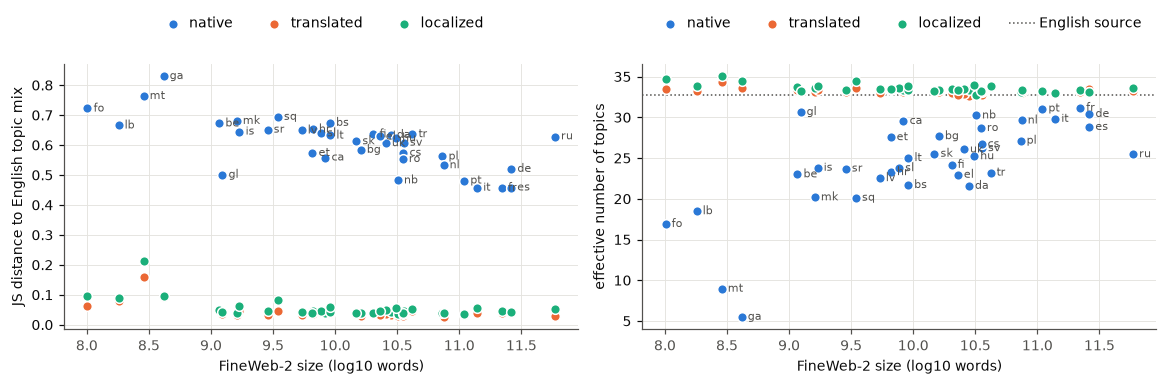

In [27]:
def js_distance(p, q):
    m = (p + q) / 2
    kl = lambda a, b: np.sum(np.where(a > 0, a * np.log2(np.where(a > 0, a, 1) / np.where(b > 0, b, 1)), 0))
    return float(np.sqrt((kl(p, m) + kl(q, m)) / 2))

def effective_topics(p):
    p = p[p > 0]
    return float(np.exp(-(p * np.log(p)).sum()))

topic_stats = pd.DataFrame([{"lang": code, "condition": cond, "effective_topics": effective_topics(dist((cond, code))),
                             "js_to_english": js_distance(dist((cond, code)), p_en)}
                            for (cond, code) in topic_lab if code != "en"])
topic_stats.to_csv(OUT_DIR / "topic_stats.csv", index=False)
print(f"English source: {effective_topics(p_en):.1f} effective topics of {N_TOPICS}")
display(topic_stats.pivot(index="lang", columns="condition", values=["effective_topics", "js_to_english"])
        .loc[sorted(LANGS, key=lambda c: -RESOURCE.get(c, 0))].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, label in [(axes[0], "js_to_english", "JS distance to English topic mix"),
                          (axes[1], "effective_topics", "effective number of topics")]:
    for cond in CONDITIONS:
        d = topic_stats[(topic_stats.condition == cond) & topic_stats.lang.isin(RESOURCE)]
        x = np.log10([RESOURCE[c] for c in d["lang"]])
        ax.scatter(x, d[metric], s=40, color=COLORS[cond], edgecolor="white", linewidth=1, zorder=3, label=cond)
        if cond == "native":
            for xi, yi, c in zip(x, d[metric], d["lang"]):
                ax.annotate(c, (xi, yi), xytext=(4, 0), textcoords="offset points", fontsize=7, color=INK_MUTED,
                            va="center")
            r = pd.Series(x).rank().corr(d[metric].reset_index(drop=True).rank())
            print(f"native {metric} vs FineWeb-2 size: Spearman ρ = {r:.2f}")
    if metric == "effective_topics":
        ax.axhline(effective_topics(p_en), color=INK_MUTED, linewidth=1, linestyle=":", label="English source")
    ax.set_xlabel("FineWeb-2 size (log10 words)")
    ax.set_ylabel(label)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=4, handletextpad=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / "topics_vs_resource.pdf", bbox_inches="tight")

### 9b. Topics from a fixed taxonomy (zero-shot)

A second topic model that does not depend on clustering: every instruction is assigned to the closest of
`len(DOMAINS)` predefined domains, by bge-m3 similarity between the instruction and a short English description of
each domain ("A question or request about …"). The categories are fixed and human-readable, so the same
comparisons can be read directly, and agreeing results from both methods are not an artefact of one clustering.

- Same sample and language centering as in section 9; the domain descriptions are centered on their own mean.
- Coarser (23 domains vs. 40 clusters) and less accurate per instruction than the clusters (see the agreement check
  below), but unbiased between native and translated data of the same language, since both are compared in the
  same language.

In [28]:
DOMAINS = {
    "Programming & software": "computer programming, code, software development, scripts, debugging",
    "Computers & technology": "computers, smartphones, apps, the internet, gadgets, settings and tech support",
    "Mathematics": "math problems, calculations, equations and statistics",
    "Natural sciences": "physics, chemistry, biology, astronomy and how things work in nature",
    "Health & medicine": "health, symptoms, illnesses, medicine, nutrition and mental health",
    "Sports & fitness": "sports, athletes, matches, exercise and training",
    "Food & cooking": "recipes, cooking, baking, food and drinks",
    "Travel & places": "travel plans, destinations, sightseeing, cities, countries and transport",
    "History": "historical events, historical periods and historical figures",
    "Politics, law & society": "politics, government, laws, legal questions, rights and social issues",
    "Business, economy & work": "business, the economy, jobs, careers, the workplace and marketing",
    "Personal finance": "money, budgets, taxes, savings, loans, insurance and prices",
    "Education & studying": "school, studying, exams, university, homework and learning",
    "Language & grammar": "grammar, spelling, word meanings, idioms, translation and language learning",
    "Writing & editing": "writing, rewriting, proofreading or summarizing texts, emails, letters and articles",
    "Literature & creative writing": "stories, poems, fiction, books and authors",
    "Arts & entertainment": "music, films, TV series, video games, art and celebrities",
    "Culture, traditions & religion": "national culture, customs, holidays, traditions, folklore and religion",
    "Relationships & family": "friends, partners, dating, family, parenting and social situations",
    "Home, garden & pets": "the household, cleaning, repairs, DIY, gardening, plants and pets",
    "Nature & environment": "nature, animals, the weather, climate and the environment",
    "Shopping & products": "buying things, product recommendations, comparisons and gifts",
    "Philosophy & ethics": "philosophical questions, morality and the meaning of life",
}
N_DOMAINS = len(DOMAINS)

enc_model, tok, device = load_encoder()
dom_emb = embed_texts([f"A question or request about {d}." for d in DOMAINS.values()], enc_model, tok, device)
del enc_model
dom_emb = dom_emb - dom_emb.mean(0)
dom_lab = {key: (e @ dom_emb.T).argmax(1) for key, e in topic_cent.items()}

def dom_dist(key):
    return np.bincount(dom_lab[key], minlength=N_DOMAINS) / len(dom_lab[key])

en_dom = dict(zip(topic_texts[("english", "en")]["id"], dom_lab[("english", "en")]))
dom_agree = {cond: np.mean([np.mean([en_dom[i] == t for i, t in zip(topic_texts[(cond, code)]["id"], dom_lab[(cond, code)])])
                            for code in LANGS if (cond, code) in dom_lab])
             for cond in ["translated", "localized"]}
print(f"Domain agreement with the English source: translated {dom_agree['translated']:.1%}, "
      f"localized {dom_agree['localized']:.1%} (chance: {1 / N_DOMAINS:.1%})")

native_tier = {t: np.mean([dom_dist(("native", c)) for c in LANGS if TIER.get(c) == t and ("native", c) in dom_lab], axis=0)
               for t in TIER_ORDER}
domains = pd.DataFrame({"English %": 100 * dom_dist(("english", "en")),
                        "translated %": 100 * np.mean([dom_dist(k) for k in dom_lab if k[0] == "translated"], axis=0),
                        **{f"native {t} %": 100 * native_tier[t] for t in TIER_ORDER}}, index=list(DOMAINS))
domains = domains.sort_values("English %", ascending=False)
domains.round(1).to_csv(OUT_DIR / "domains.csv")
display(domains.round(1))

Domain agreement with the English source: translated 73.5%, localized 72.0% (chance: 4.3%)


,English %,translated %,native high %,native mid %,native low %
Writing & editing,11.5,10.4,6.0,3.9,2.5
Food & cooking,10.2,10.2,13.9,14.7,12.5
Travel & places,9.4,9.3,8.2,7.5,5.9
Nature & environment,8.6,8.3,7.9,7.7,7.1
Natural sciences,7.6,7.2,3.2,2.3,2.1
Literature & creative writing,5.6,5.6,5.8,6.2,9.0
History,5.3,5.3,4.8,4.3,6.2
"Politics, law & society",5.1,5.7,2.4,1.6,2.0
Computers & technology,5.1,4.9,2.5,2.8,2.8
"Business, economy & work",4.5,4.3,4.0,3.1,2.5


62% of cells significant


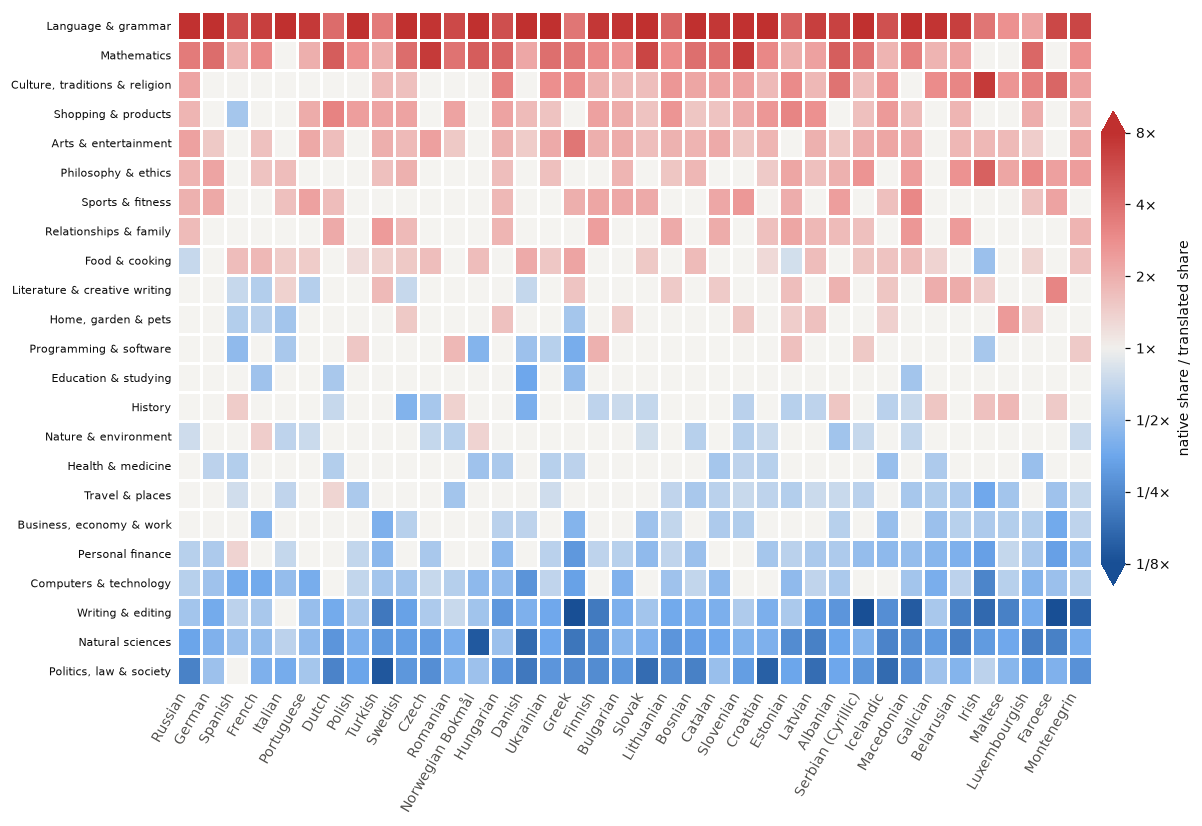

In [29]:
def compare_topics(native, translated, k, prior=2):
    '''Per topic: log2(native share / translated share), with `prior` pseudo-counts damping topics with few
    members, and the two-proportion z-test p-value for the difference in shares.'''
    a, b = np.bincount(native, minlength=k), np.bincount(translated, minlength=k)
    na, nb = a.sum(), b.sum()
    ratio = np.log2(((a + prior) / (na + k * prior)) / ((b + prior) / (nb + k * prior)))
    pooled = (a + b) / (na + nb)
    z = (a / na - b / nb) / np.sqrt(np.maximum(pooled * (1 - pooled) * (1 / na + 1 / nb), 1e-12))
    return ratio, np.array([math.erfc(abs(x) / math.sqrt(2)) for x in z])

def bh_significant(pvals, q=0.05):
    '''Benjamini–Hochberg: which p-values are significant at false discovery rate q.'''
    flat = np.asarray(pvals).ravel()
    order = np.argsort(flat)
    passed = flat[order] <= q * np.arange(1, len(flat) + 1) / len(flat)
    n_sig = np.flatnonzero(passed).max() + 1 if passed.any() else 0
    sig = np.zeros(len(flat), dtype=bool)
    sig[order[:n_sig]] = True
    return sig.reshape(np.shape(pvals))

def topic_heatmap(labels, k, row_names, title, path, row_height=0.26):
    '''Topics x languages heatmap of native vs. translated topic shares (fixed scale 1/8x to 8x). Cells whose
    difference is not significant (Benjamini–Hochberg, FDR 5%, over the whole heatmap) are left gray.'''
    langs = [c for c in sorted(LANGS, key=lambda c: -RESOURCE.get(c, 0))
             if ("native", c) in labels and ("translated", c) in labels]
    res = {c: compare_topics(labels[("native", c)], labels[("translated", c)], k) for c in langs}
    ratio = pd.DataFrame({c: r for c, (r, _) in res.items()}, index=row_names)
    sig = pd.DataFrame(bh_significant(np.column_stack([p for _, p in res.values()])), index=row_names, columns=langs)
    rows = ratio.mean(axis=1).sort_values(ascending=False).index
    ratio, sig = ratio.loc[rows], sig.loc[rows]

    cmap = DIVERGING.copy()
    cmap.set_bad("#f4f3f0")
    fig, ax = plt.subplots(figsize=(11, row_height * len(ratio) + 1.6))
    mesh = ax.pcolormesh(np.ma.masked_where(~sig.values, ratio.values), cmap=cmap, norm=TwoSlopeNorm(0, -3, 3),
                         edgecolors="white", linewidth=0.8)
    ax.set_xticks(np.arange(len(langs)) + 0.5, [LANGS[c] for c in langs], rotation=60, ha="right")
    ax.set_yticks(np.arange(len(rows)) + 0.5, rows, fontsize=7.5)
    ax.invert_yaxis()
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(mesh, ax=ax, fraction=0.025, pad=0.01, extend="both", ticks=range(-3, 4))
    cb.ax.set_yticklabels(["1/8×", "1/4×", "1/2×", "1×", "2×", "4×", "8×"])
    cb.outline.set_visible(False)
    cb.set_label("native share / translated share")
    fig.tight_layout()
    fig.savefig(OUT_DIR / path, bbox_inches="tight")
    print(f"{sig.values.mean():.0%} of cells significant")
    return ratio, sig

dom_ratio, dom_sig = topic_heatmap(dom_lab, N_DOMAINS, list(DOMAINS),
                                   "Domains in native vs. translated data, languages by FineWeb-2 size",
                                   "domains_native_vs_translated.pdf")

86% of cells significant
Most over-represented in native:


,mean log2 ratio,keywords (English members),native examples
"34: translate, pronounce, translation",3.90,"translate, pronounce, translation, spanish, tell, bonjour","[uk] привіт, можеш перекласти мені будь ласка ""to be honest with you"" українською? але таке, що | [sr] Ajde, prevedi mi ovo na engleski, ali da zvuči prirodno, a ne onako doslovno, molim te. ""Б"
"33: capital, always, doctor",3.43,"capital, always, doctor, quickly, madagascar, bolivia","[pl] nie wiem jak to się mówi po angielsku, powiedz mi po polsku 😂 | [sq] gjithmone kur po thoja 'nuk ke pse fal', ajo e kthente sikur kesh non e kisha permend. si"
"4: license, csv, remove",3.19,"license, csv, remove, fix, complaints, python","[el] ξεχασα τον κωδικο μου στην εφαρμογη του τραπεζακιου μου, πως μπορω να τον ανακτησω? | [be] гэта калісьці працавала без праблем, а зараз не памятаю, як пракансальтавацца з файлам. ча"
"10: capital, botswana, hayward",2.79,"capital, botswana, hayward, shakespeare, festival, lineup",[ga] cad é an baile is gaelaí in Éirinn? | [et] kes on Eestis kõige populaarsem koeranižn ja mis on tema hind?
"39: sound, rewrite, his",2.48,"sound, rewrite, his, often, resume, confident","[gl] Fixa o ortografía deste texto, por favor: ""as veces penso que a xente non entende o que qu | [es] cómo reescribo esto para que suene más formal? ""Necesito que revises este texto, me da com"
"0: recipe, substitute, making",1.87,"recipe, substitute, making, chicken, good, pesto","[nl] hoe zet ik een recept van chili con carne om naar een vegetarische variant, zonder dat het | [el] ρε πως μπορω να φτιαξω μια σαλτσα μπεσαμελ χωρις να εχει κοκκους;"
"16: poem, chill, write",1.77,"poem, chill, write, song, feeling, maybe","[uk] можеш мені перерахувати декілька гарних пісень для ненавмисної романтичної атмосфери, щось | [da] jeg kan egentlig godt lide den sang, men kan du finde en der lyder lidt mere upbeat og har"
"26: weather, rain, london",1.76,"weather, rain, london, usually, forecast, coat","[es] mas o menos a qué hora crees que va a llover mañana en Madrid? necesito saber para planear | [pt] rápido, vê aí se chove em Lisboa amanhã e qual a temperatura máxima esperada, por favor?"


Most under-represented in native:


,mean log2 ratio,keywords (English members),native examples
"8: new, tax, eu",-3.01,"new, tax, eu, uk, points, changes","[da] Hej, kan du lige opsummere de vigtigste punkter fra artiklen om den nye skattelov, som jeg | [pt] voce pode me resumir o artigo sobre as novas leis de impostos no Brasil? Preciso entender"
"22: sent, points, bullet",-3.69,"sent, points, bullet, article, main, summarise","[es] és posible que me resumas los puntos clave del artículo que te acabo de enviar, porfa? | [nb] men kan du bare oppsummere den artikkelen jeg sendte deg, men bare de viktigste punktene o"
"23: article, nasa, recent",-3.76,"article, nasa, recent, new, points, main","[fr] peut-tu me résumer l'article sur le nouveau satellite de la NASA, le truc sur l'étude des | [es] oye podrías resumirme el artículo este sobre la nueva misión lunar de la NASA? El link es"
"11: against, arguments, proposed",-3.78,"against, arguments, proposed, debate, main, summarise",[ro] poți să-mi faci un rezumat scurt cu principalele argumente pro și contra referitoare la im | [fr] peux tu me résumer les principaux arguments pour et contre l'augmentation du smic ? dis-mo
"3: gaza, world, theguardian",-4.14,"gaza, world, theguardian, israel, aid, www","[hr] kvazi, možeš mi prevesti ovaj tekst s engleskog na hrvatski, molim te? https://www.theguar | [it] ma mi faresti un riassunto di quest'articolo? https://ilpost.it/2024/04/26/guerra-israele-"
"27: telescope, webb, james",-4.18,"telescope, webb, james, space, finding, exoplanet","[pt] vê se consegue achar um resumo breve das descobertas mais importantes do Telescópio James | [ru] слушай, можешь мне кратко пересказать статью про космический телескоп Джеймса Уэбба? А то"
"15: points, main, summarize",-4.53,"points, main, summarize, v, court, supreme","[gl] podías resumirme os puntos clave da declaración de independentidade dos Estados Unidos nun | [pt] oi, pode me resumir os principais pontos do julgamento do 10 de janeiro? to tentando enten"
"20: nytimes, article, html",-5.16,"nytimes, article, html, trump, times, summarize","[es] oye, podrías resumirme los principales argumentos del último artículo de Larry Fink de Bla | [ro] vrei sa imi faci un rezumat scurt la articolul ăsta, te rog? https://www.nytimes.com/2024/"


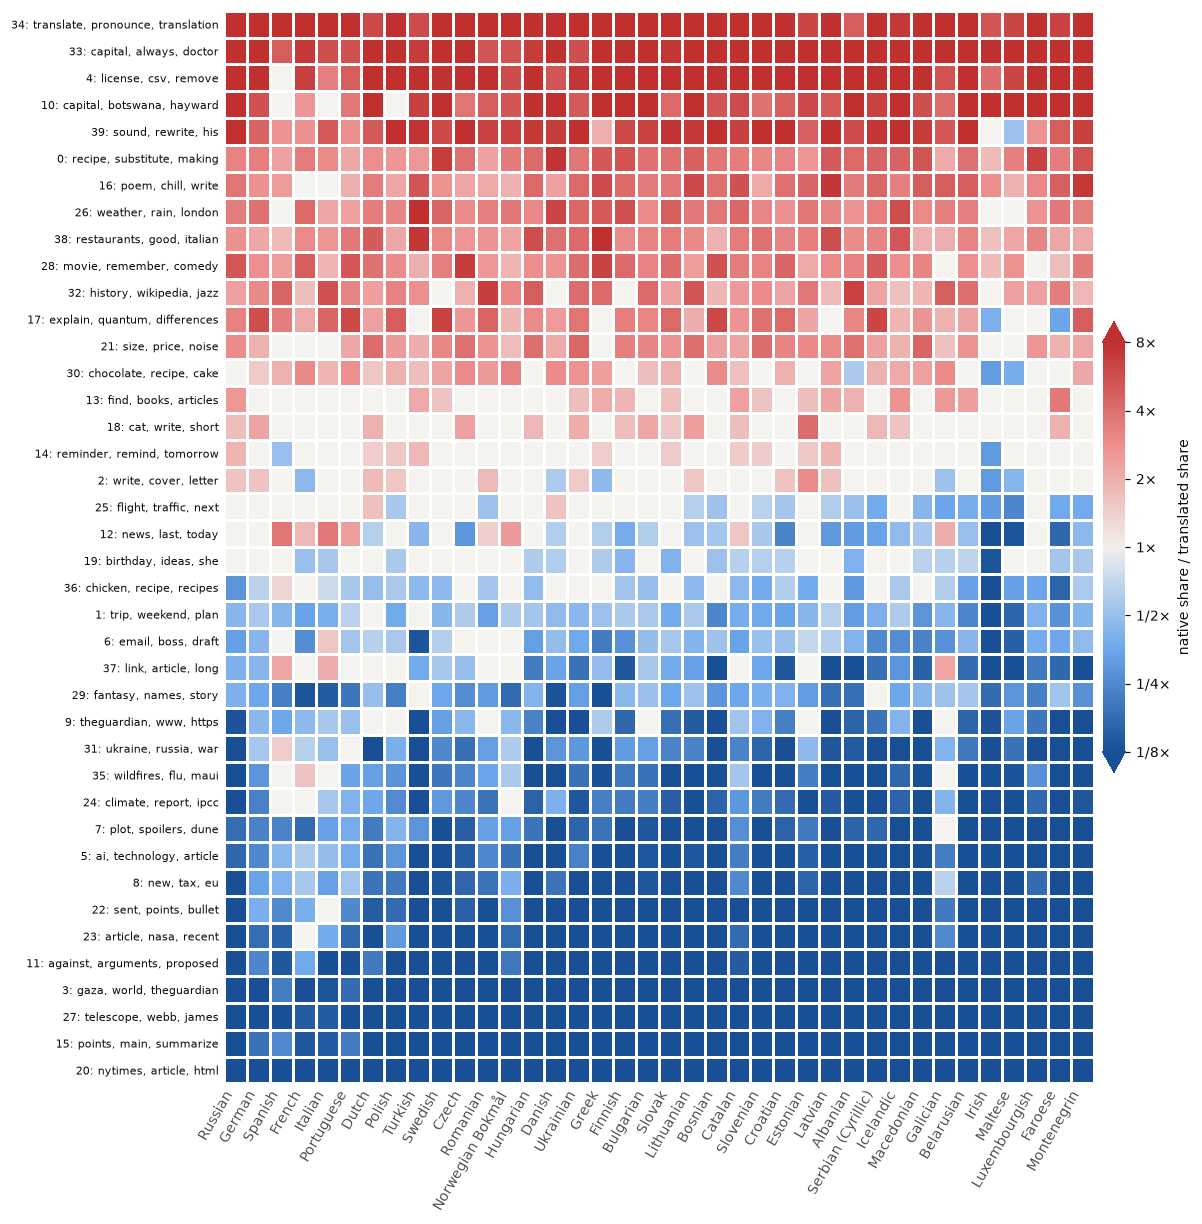

In [30]:
# The same for the 40 clusters. Each cluster is labelled with its top c-TF-IDF keywords from the English source
# (clusters that are mostly native have few English members, so few keywords).
topic_names = [f"{t}: {', '.join(keywords[t].split(', ')[:3]) if t in keywords else '(few English members)'}"
               for t in range(N_TOPICS)]
ratio, ratio_sig = topic_heatmap(topic_lab, N_TOPICS, topic_names,
                                 "Topic clusters in native vs. translated data, languages by FineWeb-2 size",
                                 "topics_native_vs_translated.pdf", row_height=0.24)

summary_t = topics[["keywords (English members)", "native examples"]].sort_index()   # topic id order
summary_t.index = topic_names
summary_t = summary_t.loc[ratio.index]
summary_t.insert(0, "mean log2 ratio", ratio.mean(axis=1).round(2))
print("Most over-represented in native:")
display(summary_t.head(8))
print("Most under-represented in native:")
display(summary_t.tail(8))

### 9c. Which languages' topic mix changes most?

**Metric: total variation distance (TVD)** between the topic distribution of a language's native data and of its
translated data, TVD = ½ Σ |p_native − p_translated|. It is the share of the native data that would have to move to
another topic to reproduce the translated (= English source) topic mix: 0 = identical, 1 = no overlap. It reads
directly as a percentage, and it splits into per-topic contributions, so the topics behind a language's shift can be
listed exactly.

- Computed for both topic models (40 clusters, 23 domains); agreement between the two rankings shows the result does
  not depend on the method.
- 95% bootstrap intervals (resampling both sets). The **noise floor** is the expected TVD between two samples of the
  same sizes drawn from one distribution. TVD is biased upward by sampling noise, which matters most for the
  40-cluster model.
- Localized vs. translated is shown in the table as a reference: how much localization alone moves the topic mix.

In [31]:
def tvd(p, q):
    return 0.5 * float(np.abs(p - q).sum())

def topic_change(labels, k, cond="native", n_boot=1000):
    '''TVD between cond and translated topic distributions per language, with bootstrap CI and noise floor.'''
    rng = np.random.default_rng(SEED)
    rows = {}
    for code in LANGS:
        if (cond, code) not in labels or ("translated", code) not in labels:
            continue
        ca, cb = (np.bincount(labels[(c, code)], minlength=k) for c in (cond, "translated"))
        na, nb = ca.sum(), cb.sum()
        pa, pb = ca / na, cb / nb
        boot = 0.5 * np.abs(rng.multinomial(na, pa, n_boot) / na - rng.multinomial(nb, pb, n_boot) / nb).sum(1)
        pool = (ca + cb) / (na + nb)
        floor = 0.5 * np.abs(rng.multinomial(na, pool, n_boot) / na - rng.multinomial(nb, pool, n_boot) / nb).sum(1)
        rows[code] = {"tvd": tvd(pa, pb), "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5),
                      "floor": floor.mean(), "diff": pa - pb}
    return rows

change = {"clusters": topic_change(topic_lab, N_TOPICS), "domains": topic_change(dom_lab, N_DOMAINS)}
loc_change = {"clusters": topic_change(topic_lab, N_TOPICS, "localized"),
              "domains": topic_change(dom_lab, N_DOMAINS, "localized")}

def top_moves(diff, names, n=2):
    order = np.argsort(diff)
    up = [f"{names[i]} +{100 * diff[i]:.0f}" for i in order[::-1][:n] if diff[i] > 0]
    down = [f"{names[i]} −{-100 * diff[i]:.0f}" for i in order[:n] if diff[i] < 0]
    return "; ".join(up), "; ".join(down)

dom_names = list(DOMAINS)
change_tab = pd.DataFrame({
    code: {"tier": TIER.get(code),
           "TVD clusters %": 100 * change["clusters"][code]["tvd"],
           "TVD domains %": 100 * change["domains"][code]["tvd"],
           "localized: TVD domains %": 100 * loc_change["domains"][code]["tvd"] if code in loc_change["domains"] else np.nan,
           "more in native (pp)": top_moves(change["domains"][code]["diff"], dom_names)[0],
           "less in native (pp)": top_moves(change["domains"][code]["diff"], dom_names)[1]}
    for code in change["clusters"] if code in change["domains"]}).T
change_tab = change_tab.sort_values("TVD clusters %", ascending=False)
change_tab.index = [LANGS[c] for c in change_tab.index]
change_tab.to_csv(OUT_DIR / "topic_change.csv")

codes = list(change["clusters"])
ranks = lambda m: pd.Series([change[m][c]["tvd"] for c in codes]).rank()
print(f"Rank agreement of the two methods: Spearman ρ = {ranks('clusters').corr(ranks('domains')):.2f}")
sized = [c for c in codes if c in RESOURCE]
size_rank = pd.Series([RESOURCE[c] for c in sized]).rank()
for m in change:
    r = size_rank.corr(pd.Series([change[m][c]["tvd"] for c in sized]).rank())
    floor = np.mean([change[m][c]["floor"] for c in codes])
    print(f"{m}: TVD native vs. translated {np.mean([change[m][c]['tvd'] for c in codes]):.1%} on average "
          f"(noise floor {floor:.1%}); vs. FineWeb-2 size: Spearman ρ = {r:.2f}")
display(change_tab.round(1))

Rank agreement of the two methods: Spearman ρ = 0.63
clusters: TVD native vs. translated 58.0% on average (noise floor 7.7%); vs. FineWeb-2 size: Spearman ρ = -0.74
domains: TVD native vs. translated 27.1% on average (noise floor 5.6%); vs. FineWeb-2 size: Spearman ρ = -0.58


,tier,TVD clusters %,TVD domains %,localized: TVD domains %,more in native (pp),less in native (pp)
Irish,low,79.0,36.05,6.15,"Culture, traditions & religion +10; Philosophy & ethics +8",Writing & editing −9; Travel & places −6
Maltese,low,70.55,24.75,6.85,"Philosophy & ethics +5; Culture, traditions & religion +4",Writing & editing −7; Natural sciences −5
Faroese,low,69.25,37.5,6.6,"Literature & creative writing +11; Culture, traditions & religion +6",Writing & editing −15; Natural sciences −5
Albanian,low,68.0,29.9,4.15,Language & grammar +5; Literature & creative writing +5,Writing & editing −7; Natural sciences −5
Belarusian,low,64.85,29.1,6.7,Language & grammar +8; Literature & creative writing +6,Writing & editing −8; Natural sciences −6
Montenegrin,low,64.55,30.35,3.75,Food & cooking +7; Language & grammar +6,Writing & editing −10; Natural sciences −4
Macedonian,low,64.15,35.45,6.6,Language & grammar +11; Food & cooking +8,Writing & editing −11; Natural sciences −5
Bosnian,mid,63.7,30.7,4.35,Language & grammar +9; Food & cooking +8,Writing & editing −6; Natural sciences −5
Croatian,mid,62.85,25.85,2.75,Language & grammar +9; Arts & entertainment +4,"Writing & editing −6; Politics, law & society −5"
Luxembourgish,low,62.5,25.9,4.3,"Culture, traditions & religion +5; Philosophy & ethics +5",Writing & editing −6; Natural sciences −6


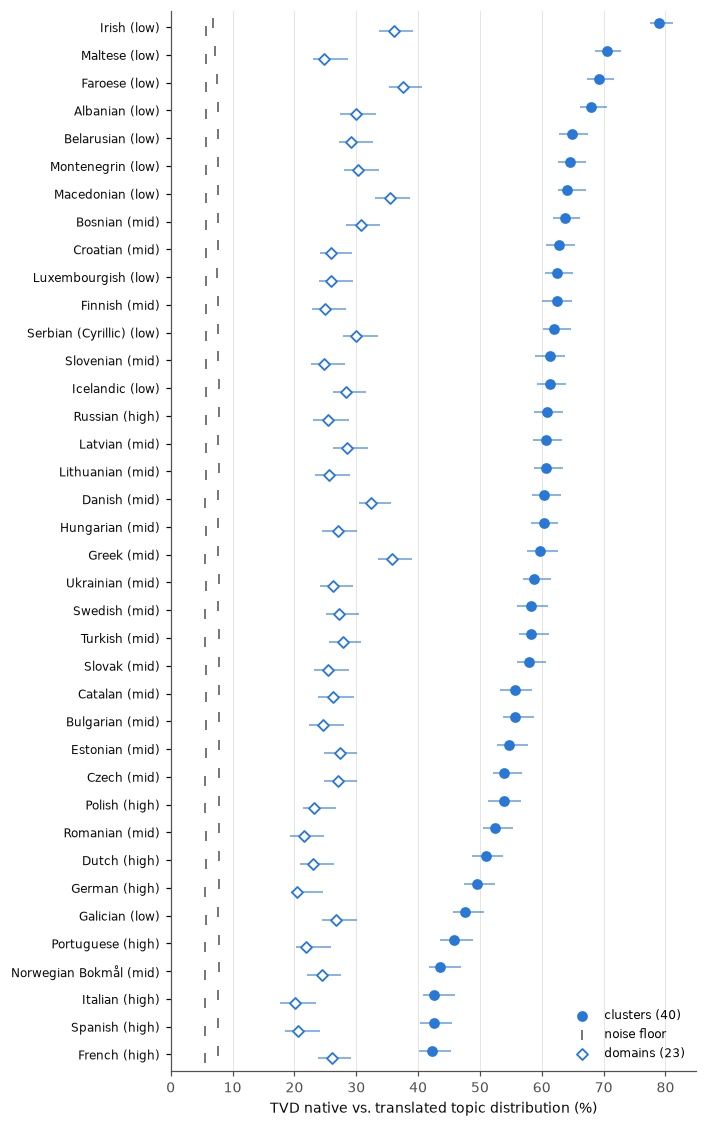

In [32]:
# Ranked dot plot: one row per language, both topic models; whiskers = 95% bootstrap interval, gray tick = noise floor
order_c = sorted(codes, key=lambda c: change["clusters"][c]["tvd"])
fig, ax = plt.subplots(figsize=(6.5, 0.24 * len(order_c) + 1.2))
y = np.arange(len(order_c))
for m, marker, face, dy in [("clusters", "o", COLORS["native"], 0.14), ("domains", "D", "white", -0.14)]:
    v = np.array([change[m][c]["tvd"] for c in order_c]) * 100
    lo = np.array([change[m][c]["lo"] for c in order_c]) * 100
    hi = np.array([change[m][c]["hi"] for c in order_c]) * 100
    ax.hlines(y + dy, lo, hi, color=COLORS["native"], linewidth=1.2, alpha=0.6)
    ax.scatter(v, y + dy, marker=marker, s=34 if marker == "o" else 26, facecolor=face, edgecolor=COLORS["native"],
               linewidth=1.2, zorder=3, label=f"{m} ({N_TOPICS if m == 'clusters' else N_DOMAINS})")
    floor = np.array([change[m][c]["floor"] for c in order_c]) * 100
    ax.scatter(floor, y + dy, marker="|", s=40, color=INK_MUTED, linewidth=1, zorder=2,
               label="noise floor" if m == "clusters" else None)
ax.set_yticks(y, [f"{LANGS[c]} ({TIER.get(c, '-')})" for c in order_c], fontsize=8)
ax.set_ylim(-0.6, len(order_c) - 0.4)
ax.set_xlim(left=0)
ax.set_xlabel("TVD native vs. translated topic distribution (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "topic_change_tvd.pdf", bbox_inches="tight")

### 9d. Robustness: other topic models

Do the 9c results depend on the clustering algorithm? The TVD native vs. translated is recomputed with three more
topic models:

- **GMM (40)**: Gaussian mixture (diagonal covariance) on the same language-centered embeddings, reduced to 64
  dimensions with PCA. Soft, elliptical clusters instead of k-means' hard, spherical ones.
- **Ward (40)**: agglomerative clustering with Ward linkage on a subsample of `WARD_FIT_N` embeddings; the remaining
  instructions are assigned to the nearest cluster centroid. Hierarchical, with no centroid initialisation.
- **LDA (20)**: latent Dirichlet allocation on bags of words, with no embedding model. Fitted separately for each
  language on its native + translated instructions, so its topics are not aligned across languages, but native and
  translated are compared on the same topics. Each instruction gets its most probable topic. Words in more than 2% of
  the instructions are dropped. With a looser cutoff (20%), LDA's topics are built from register words, such as
  colloquial German *hab, mal, nen* in native data vs. *hey, okay, also* in translated data. They then measure style
  rather than topic, and the TVD rises to over 60%.

GMM and Ward reproduce the k-means ranking almost exactly. LDA confirms that native and translated data differ
in topic in every language (TVD far above the noise floor), but its ranking of languages is not comparable to the
others: each language gets its own vocabulary and model, whose quality depends on morphology and data size.

In [33]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA, LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import normalized_mutual_info_score
from sklearn.mixture import GaussianMixture

N_LDA = 20            # LDA topics per language
WARD_FIT_N = 10000    # Ward linkage is quadratic in memory: fit on a subsample, assign the rest to the nearest centroid
alt_lab = {}

# (1) Gaussian mixture on the same language-centered embeddings (PCA to 64 dims): soft, elliptical clusters
# instead of k-means' hard, spherical ones.
pca = PCA(64, random_state=SEED).fit(fit)
gmm = GaussianMixture(N_TOPICS, covariance_type="diag", n_init=2, random_state=SEED).fit(pca.transform(fit))
alt_lab["GMM"] = {key: gmm.predict(pca.transform(e)) for key, e in topic_cent.items()}

# (2) Agglomerative clustering (Ward linkage): hierarchical, no centroid initialisation.
sub = fit[np.random.default_rng(SEED).choice(len(fit), min(WARD_FIT_N, len(fit)), replace=False)]
ward = AgglomerativeClustering(N_TOPICS, linkage="ward").fit_predict(sub)
ward_c = np.stack([sub[ward == j].mean(0) for j in range(N_TOPICS)])
ward_c /= np.linalg.norm(ward_c, axis=1, keepdims=True)
alt_lab["Ward"] = {key: (e @ ward_c.T).argmax(1) for key, e in topic_cent.items()}

# (3) LDA on bags of words: no embedding model at all. Topics are fitted per language on its native + translated
# instructions (shared vocabulary), so they are not aligned across languages, but native vs. translated is.
# Each instruction gets its most probable topic.
def lda_labels(code):
    keys = [(c, code) for c in CONDITIONS if (c, code) in topic_texts]
    texts = {k: topic_texts[k]["instruction"].fillna("").tolist() for k in keys}
    vec = CountVectorizer(token_pattern=r"(?u)\b[^\W\d_]{3,}\b", min_df=5, max_df=0.02)
    X_fit = vec.fit_transform(texts[("native", code)] + texts[("translated", code)])
    lda = LatentDirichletAllocation(N_LDA, learning_method="batch", max_iter=30, random_state=SEED).fit(X_fit)
    return {k: lda.transform(vec.transform(t)).argmax(1) for k, t in texts.items()}

alt_lab["LDA"] = {}
for code in LANGS:
    if ("native", code) in topic_texts and ("translated", code) in topic_texts:
        alt_lab["LDA"].update(lda_labels(code))

# Do the embedding-based partitions agree with k-means? (NMI on all native + translated instructions)
pool = [k for k in topic_lab if k[0] in ("native", "translated")]
for m in ("GMM", "Ward"):
    nmi = normalized_mutual_info_score(np.concatenate([topic_lab[k] for k in pool]),
                                       np.concatenate([alt_lab[m][k] for k in pool]))
    print(f"{m} vs. k-means partition: NMI = {nmi:.2f}")

GMM vs. k-means partition: NMI = 0.69
Ward vs. k-means partition: NMI = 0.71


In [34]:
# TVD native vs. translated per language for every topic model, as in 9c
methods = {"k-means (40)": (topic_lab, N_TOPICS), "domains (23)": (dom_lab, N_DOMAINS),
           "GMM (40)": (alt_lab["GMM"], N_TOPICS), "Ward (40)": (alt_lab["Ward"], N_TOPICS),
           "LDA (20)": (alt_lab["LDA"], N_LDA)}
all_change = {m: topic_change(lab, k) for m, (lab, k) in methods.items()}
codes_all = [c for c in LANGS if all(c in all_change[m] for m in methods)]
tvd_tab = pd.DataFrame({m: {LANGS[c]: 100 * all_change[m][c]["tvd"] for c in codes_all} for m in methods})
excess = pd.DataFrame({m: {LANGS[c]: 100 * (all_change[m][c]["tvd"] - all_change[m][c]["floor"]) for c in codes_all}
                       for m in methods})

summary_m = pd.DataFrame({
    "mean TVD %": tvd_tab.mean(), "noise floor %": [100 * np.mean([all_change[m][c]["floor"] for c in codes_all])
                                                   for m in methods],
    "ρ with FineWeb-2 size": [pd.Series([RESOURCE[c] for c in codes_all if c in RESOURCE]).rank()
                               .corr(pd.Series([all_change[m][c]["tvd"] for c in codes_all if c in RESOURCE]).rank())
                               for m in methods]})
print("Per method (Spearman ρ across languages; negative = larger shift in smaller languages):")
display(summary_m.round(2))
print("Rank agreement between methods (Spearman ρ of the per-language TVD):")
display(tvd_tab.corr(method="spearman").round(2))
tvd_tab.round(1).to_csv(OUT_DIR / "topic_change_methods.csv")
display(tvd_tab.loc[tvd_tab.mean(axis=1).sort_values(ascending=False).index].round(1))

Per method (Spearman ρ across languages; negative = larger shift in smaller languages):


,mean TVD %,noise floor %,ρ with FineWeb-2 size
k-means (40),57.99,7.67,-0.74
domains (23),27.06,5.65,-0.58
GMM (40),60.16,7.53,-0.73
Ward (40),59.40,7.54,-0.73
LDA (20),29.87,5.46,-0.04


Rank agreement between methods (Spearman ρ of the per-language TVD):


,k-means (40),domains (23),GMM (40),Ward (40),LDA (20)
k-means (40),1.00,0.63,0.96,0.98,0.35
domains (23),0.63,1.00,0.60,0.66,0.35
GMM (40),0.96,0.60,1.00,0.96,0.38
Ward (40),0.98,0.66,0.96,1.00,0.40
LDA (20),0.35,0.35,0.38,0.40,1.00


,k-means (40),domains (23),GMM (40),Ward (40),LDA (20)
Irish,79.0,36.0,75.4,81.0,31.5
Faroese,69.2,37.5,71.4,71.2,28.8
Albanian,68.0,29.9,69.3,69.8,37.4
Montenegrin,64.6,30.4,67.4,67.0,42.1
Bosnian,63.7,30.7,65.8,65.4,37.6
Macedonian,64.1,35.4,67.4,66.4,27.7
Finnish,62.4,25.0,65.1,63.9,42.6
Greek,59.6,35.8,60.1,64.0,39.4
Serbian (Cyrillic),62.0,30.0,65.8,64.2,34.6
Belarusian,64.8,29.1,69.0,67.6,25.4


## 10. Named entities: whose knowledge?

Which specific people, places, organisations, works and events does each set mention, how many distinct ones, and
how many of them would never reach a language through translation of the English source?

- **Extraction** (`exp/extract_entities.py`, GPU): Gemma 3 27B lists the named entities in instruction + response,
  each with its **canonical English name** (so inflected and translated mentions match across languages) and the
  **country** it is most associated with. Same samples as section 9 (`TOPIC_N` per set; translated/localized are
  the English source ids). Copy the output to `ENT_DIR` before running this section.
- **Unit**: an entity mention, counted once per sample.
- **Diversity**: Hill–Shannon diversity exp(H) of the entity distribution (the effective number of distinct
  entities), compared at **equal estimated sample coverage** (Chao–Jost coverage from singletons and doubletons;
  every set is subsampled to the lowest coverage of all sets, averaged over `RAREFY_REPS` draws), following
  Wright et al. (2025). Without this, sets with more mentions would look more diverse only because they are bigger.
- **Not in English source**: share of mentions whose entity does not occur in the English source sample. The
  translated sets' value is the noise floor (extraction/canonicalisation disagreement on the same content).
- **Local / anglophone**: share of mentions whose associated country is one where the language is spoken
  (`LANG_COUNTRIES`, including historical states), or the US/UK/Ireland/Canada/Australia/New Zealand.

In [35]:
import json
import unicodedata

ENT_DIR = Path("../data/entities")    # <- rsync from /proj/dl4nlp/users/x_jenku/magpie/data/entities
RAREFY_REPS = 20

LANG_COUNTRIES = {
    "de": ["Germany", "Austria", "Switzerland", "Liechtenstein", "East Germany", "West Germany", "Prussia"],
    "fr": ["France", "Belgium", "Switzerland", "Luxembourg", "Monaco"],
    "es": ["Spain", "Mexico", "Argentina", "Colombia", "Chile", "Peru", "Venezuela", "Cuba", "Ecuador", "Bolivia",
           "Uruguay", "Paraguay", "Guatemala", "Honduras", "El Salvador", "Nicaragua", "Costa Rica", "Panama",
           "Dominican Republic", "Puerto Rico"],
    "it": ["Italy", "San Marino", "Vatican City", "Switzerland"], "pt": ["Portugal", "Brazil", "Angola", "Mozambique"],
    "ru": ["Russia", "Soviet Union"], "pl": ["Poland"], "nl": ["Netherlands", "Belgium", "Suriname"],
    "sv": ["Sweden"], "da": ["Denmark", "Greenland", "Faroe Islands"], "nb": ["Norway"],
    "cs": ["Czech Republic", "Czechoslovakia"], "ro": ["Romania", "Moldova"], "uk": ["Ukraine", "Soviet Union"],
    "hu": ["Hungary", "Austria-Hungary"], "fi": ["Finland"], "bg": ["Bulgaria"], "ca": ["Spain", "Andorra"],
    "hr": ["Croatia", "Yugoslavia"], "sk": ["Slovakia", "Czechoslovakia"], "sr": ["Serbia", "Yugoslavia"],
    "sl": ["Slovenia", "Yugoslavia"], "et": ["Estonia"], "be": ["Belarus", "Soviet Union"],
    "mk": ["North Macedonia", "Yugoslavia"], "gl": ["Spain"], "is": ["Iceland"], "fo": ["Faroe Islands", "Denmark"],
    "lb": ["Luxembourg"],
    "el": ["Greece", "Cyprus"], "ga": ["Ireland"], "lv": ["Latvia"], "lt": ["Lithuania"], "mt": ["Malta"],
    "sq": ["Albania", "Kosovo"], "bs": ["Bosnia and Herzegovina", "Yugoslavia"], "cnr": ["Montenegro", "Yugoslavia"],
    "tr": ["Turkey", "Ottoman Empire"],
}
ANGLO = {"United States", "United Kingdom", "Ireland", "Canada", "Australia", "New Zealand"}
COUNTRY_ALIASES = {
    "usa": "United States", "us": "United States", "u.s.": "United States", "united states of america": "United States",
    "america": "United States", "uk": "United Kingdom", "u.k.": "United Kingdom", "great britain": "United Kingdom",
    "britain": "United Kingdom", "england": "United Kingdom", "scotland": "United Kingdom", "wales": "United Kingdom",
    "northern ireland": "United Kingdom", "czechia": "Czech Republic", "macedonia": "North Macedonia",
    "republic of north macedonia": "North Macedonia", "russian federation": "Russia", "ussr": "Soviet Union",
    "the netherlands": "Netherlands", "holland": "Netherlands", "faroes": "Faroe Islands", "türkiye": "Turkey",
    "republic of ireland": "Ireland", "vatican": "Vatican City", "holy see": "Vatican City",
}

def entity_key(name):
    '''Matching key for canonical names: Unicode-normalised, case-folded, leading article and punctuation removed.'''
    s = unicodedata.normalize("NFKC", name).casefold().strip()
    s = re.sub(r"^the\s+", "", s)
    return re.sub(r"[\s\.\-'’,]+", " ", s).strip()

def norm_country(c):
    if not c:
        return None
    c = unicodedata.normalize("NFKC", c).strip()
    return COUNTRY_ALIASES.get(c.casefold(), c)

def load_entities(cond, code):
    path = ENT_DIR / f"{cond}_{code}.jsonl"
    if not path.exists():
        return None
    rows = [json.loads(l) for l in open(path, encoding="utf-8") if l.strip()]
    return pd.DataFrame([{"id": r["id"], "key": entity_key(e["name"]), "name": e["name"], "type": e["type"],
                          "country": norm_country(e["country"])}
                         for r in rows for e in r["entities"]]).assign(n_samples=len(rows))

ents = {("english", "en"): load_entities("english", "en")}
for code in LANGS:
    for cond in CONDITIONS:
        ents[(cond, code)] = load_entities(cond, code)
missing = [k for k, v in ents.items() if v is None]
ents = {k: v for k, v in ents.items() if v is not None}
print(f"{len(ents)} sets loaded" + (f", missing: {missing[:6]}{' ...' if len(missing) > 6 else ''}" if missing else ""))

88 sets loaded, missing: [('native', 'tr'), ('translated', 'tr'), ('localized', 'tr'), ('native', 'el'), ('translated', 'el'), ('localized', 'el')] ...


In [36]:
if not ents:
    print("No entity files in ENT_DIR yet: run exp/extract_entities.py on the cluster first.")
else:
    def coverage(counts):
        '''Chao–Jost estimate of sample coverage from singleton (f1) and doubleton (f2) counts.'''
        counts = np.asarray(counts)
        n, f1, f2 = counts.sum(), (counts == 1).sum(), (counts == 2).sum()
        if n <= 1 or f1 == 0:
            return 1.0
        return float(1 - f1 / n * ((n - 1) * f1 / ((n - 1) * f1 + 2 * f2)))

    def hill_shannon(counts):
        p = np.asarray(counts, dtype=float)
        p = p[p > 0] / p.sum()
        return float(np.exp(-(p * np.log(p)).sum()))

    def rarefied_hill_shannon(keys, target, reps=RAREFY_REPS, seed=SEED):
        '''Mean Hill–Shannon diversity of random subsamples of the mention list whose coverage matches `target`.'''
        keys = np.asarray(keys)
        rng = np.random.default_rng(seed)
        out = []
        for _ in range(reps):
            perm = keys[rng.permutation(len(keys))]
            lo, hi = 1, len(perm)
            while lo < hi:                       # smallest prefix with coverage >= target
                mid = (lo + hi) // 2
                if coverage(np.unique(perm[:mid], return_counts=True)[1]) >= target:
                    hi = mid
                else:
                    lo = mid + 1
            out.append(hill_shannon(np.unique(perm[:lo], return_counts=True)[1]))
        return float(np.mean(out))

    en_keys = set(ents[("english", "en")]["key"]) if ("english", "en") in ents else set()
    cov = {k: coverage(d["key"].value_counts().values) for k, d in ents.items()}
    target_cov = min(cov.values())
    print(f"Coverage before rarefaction: {min(cov.values()):.3f}-{max(cov.values()):.3f}; all sets rarefied to {target_cov:.3f}")

    ent_rows = []
    for (cond, code), d in ents.items():
        local = set(LANG_COUNTRIES.get(code, []))
        ent_rows.append({
            "lang": code, "tier": TIER.get(code), "condition": cond, "samples": d["n_samples"].iloc[0],
            "mentions_per_sample": len(d) / d["n_samples"].iloc[0],
            "distinct": d["key"].nunique(), "coverage": cov[(cond, code)],
            "hill_shannon": rarefied_hill_shannon(d["key"].values, target_cov),
            "not_in_english": float((~d["key"].isin(en_keys)).mean()) if code != "en" else np.nan,
            "local_share": float(d["country"].isin(local).mean()) if code != "en" else np.nan,
            "anglo_share": float(d["country"].isin(ANGLO).mean()),
            "no_country_share": float(d["country"].isna().mean()),
        })
    ent_stats = pd.DataFrame(ent_rows)
    ent_stats.to_csv(OUT_DIR / "entity_stats.csv", index=False)
    en_row = ent_stats[ent_stats.lang == "en"]
    if len(en_row):
        print("English source: " + ", ".join(f"{c} {en_row[c].iloc[0]:.3g}" for c in
                                              ["mentions_per_sample", "distinct", "hill_shannon", "anglo_share"]))
    display(ent_stats[ent_stats.lang != "en"]
            .pivot(index="lang", columns="condition",
                   values=["mentions_per_sample", "hill_shannon", "not_in_english", "local_share", "anglo_share"])
            .loc[[c for c in sorted(LANGS, key=lambda c: -RESOURCE.get(c, 0)) if c in set(ent_stats.lang)]].round(3))

Coverage before rarefaction: 0.357-0.614; all sets rarefied to 0.357
English source: mentions_per_sample 8.78, distinct 1.03e+04, hill_shannon 2.49e+03, anglo_share 0.32


mentions_per_sample                   hill_shannon                      not_in_english                   local_share                   anglo_share                  
condition           localized native translated    localized    native translated      localized native translated   localized native translated   localized native translated
lang                                                                                                                                                                          
ru                      8.842  6.078      8.953     3257.005  6226.300   3072.353          0.433  0.798      0.364       0.030  0.268      0.008       0.277  0.114      0.288
de                      8.822  5.714      8.884     2671.640  3461.211   2685.065          0.380  0.784      0.317       0.030  0.292      0.009       0.303  0.086      0.314
es                      8.792  7.120      8.828     2785.462  1177.813   2716.792          0.416  0.730      0.354       0.020  0.286      0.013       0.313  0.098      0.312
fr                      8.852  6.444      8.795     2474.104  1642.393   2658.655          0.402  0.773      0.331       0.031  0.330      0.012       0.288  0.094      0.306
it                      8.851  5.894      8.810     2550.450  1337.011   2651.960          0.393  0.721      0.336       0.056  0.401      0.027       0.284  0.079      0.301
pt                      8.773  6.718      8.761     2801.104  1574.063   2827.232          0.421  0.781      0.341       0.036  0.367      0.004       0.283  0.086      0.310
nl                      8.884  6.312      8.796     2602.506  3704.248   2776.182          0.373  0.795      0.311       0.027  0.269      0.002       0.292  0.083      0.301
pl                      8.629  4.708      8.640     2890.526  3485.480   2920.043          0.428  0.802      0.351       0.028  0.272      0.003       0.284  0.083      0.298
sv                      8.976  5.305      8.786     2637.618  3217.545   2725.289          0.391  0.811      0.305       0.034  0.285      0.002       0.276  0.095      0.311
cs                      8.774  5.884      8.856     2825.321  3015.641   2830.619          0.411  0.817      0.338       0.024  0.202      0.001       0.288  0.101      0.297
ro                      9.002  5.724      8.796     2874.827  2691.354   2878.930          0.417  0.789      0.331       0.031  0.257      0.001       0.250  0.090      0.289
nb                      8.706  6.073      8.680     2785.526  1146.003   2673.060          0.368  0.768      0.297       0.032  0.333      0.003       0.289  0.075      0.312
hu                      8.952  6.061      8.948     3221.529  5404.251   2956.242          0.439  0.827      0.376       0.027  0.305      0.004       0.280  0.086      0.299
da                      8.738  5.195      8.834     2523.635  1389.940   2610.187          0.383  0.780      0.299       0.051  0.316      0.004       0.264  0.070      0.300
uk                      8.900  6.156      8.960     3238.208  2880.882   3268.432          0.442  0.774      0.379       0.025  0.320      0.010       0.260  0.088      0.272
fi                      8.544  6.702      8.725     2907.377  4289.816   2905.235          0.388  0.809      0.325       0.029  0.264      0.002       0.291  0.111      0.313
bg                      8.668  5.492      8.650     3335.832  4237.042   3066.852          0.463  0.798      0.379       0.026  0.286      0.002       0.249  0.085      0.279
sk                      8.775  5.950      8.624     2798.493  2816.638   2876.877          0.389  0.829      0.319       0.019  0.220      0.001       0.272  0.090      0.298
ca                      8.892  6.286      8.782     2986.096  3417.464   3073.070          0.393  0.788      0.346       0.025  0.310      0.007       0.282  0.100      0.290
sl                      8.613  4.566      8.542     3078.929  4756.632   2948.061          0.383  0.810      0.308       0.018  0.248      0.001       0.267  0.

native hill_shannon vs FineWeb-2 size: Spearman ρ = -0.28
native not_in_english vs FineWeb-2 size: Spearman ρ = -0.39
native local_share vs FineWeb-2 size: Spearman ρ = 0.18
native anglo_share vs FineWeb-2 size: Spearman ρ = 0.15


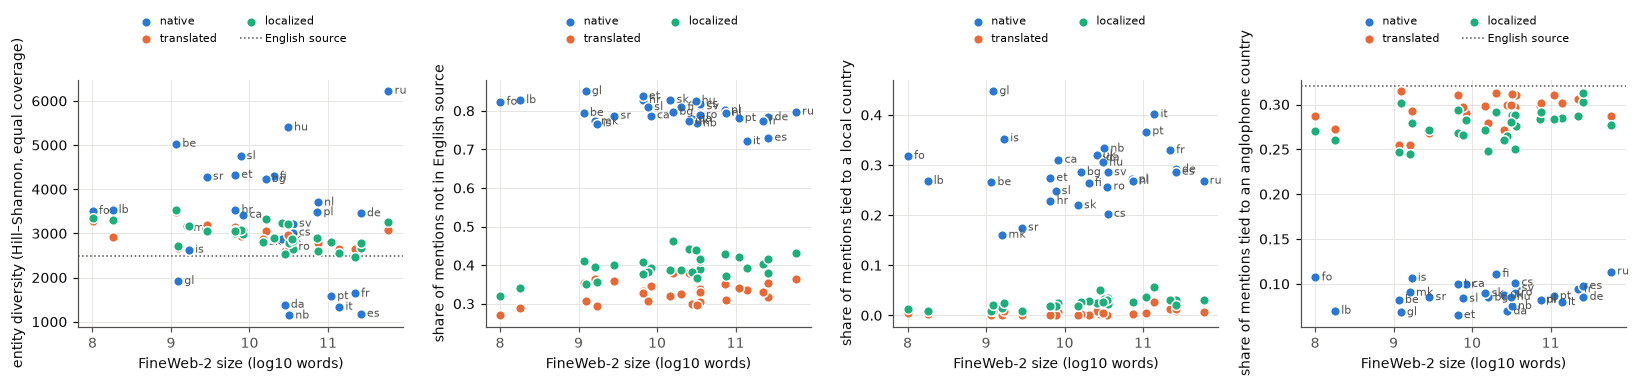

In [37]:
if ents:
    panels = [("hill_shannon", "entity diversity (Hill–Shannon, equal coverage)"),
              ("not_in_english", "share of mentions not in English source"),
              ("local_share", "share of mentions tied to a local country"),
              ("anglo_share", "share of mentions tied to an anglophone country")]
    fig, axes = plt.subplots(1, len(panels), figsize=(15, 3.6))
    for ax, (metric, label) in zip(axes, panels):
        for cond in CONDITIONS:
            d = ent_stats[(ent_stats.condition == cond) & ent_stats.lang.isin(RESOURCE)]
            if not len(d):
                continue
            x = np.log10([RESOURCE[c] for c in d["lang"]])
            ax.scatter(x, d[metric], s=40, color=COLORS[cond], edgecolor="white", linewidth=1, zorder=3, label=cond)
            if cond == "native":
                for xi, yi, c in zip(x, d[metric], d["lang"]):
                    ax.annotate(c, (xi, yi), xytext=(4, 0), textcoords="offset points", fontsize=7, color=INK_MUTED,
                                va="center")
                r = pd.Series(x).rank().corr(d[metric].reset_index(drop=True).rank())
                print(f"native {metric} vs FineWeb-2 size: Spearman ρ = {r:.2f}")
        if metric in ("hill_shannon", "anglo_share") and len(en_row):
            ax.axhline(en_row[metric].iloc[0], color=INK_MUTED, linewidth=1, linestyle=":", label="English source")
        ax.set_xlabel("FineWeb-2 size (log10 words)")
        ax.set_ylabel(label, fontsize=9)
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.1), ncol=2, handletextpad=0.2, fontsize=7.5)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "entities_vs_resource.pdf", bbox_inches="tight")

In [38]:
if ents:
    # What native generation and localized translation talk about that the English source does not: most frequent
    # entities absent from the English source sample, and the countries the set's entities are most associated with.
    for cond in ("native", "localized"):
        examples = []
        for code in sorted(LANGS, key=lambda c: -RESOURCE.get(c, 0)):
            d = ents.get((cond, code))
            if d is None:
                continue
            only = d[~d["key"].isin(en_keys)]
            top = only.groupby("key").agg(name=("name", "first"), n=("id", "size")).sort_values("n", ascending=False)
            countries = d["country"].value_counts(normalize=True).head(4)
            examples.append({"language": LANGS[code],
                             f"top {cond}-only entities": ", ".join(f"{r.name} ({r.n})" for r in top.head(8).itertuples()),
                             "top countries": ", ".join(f"{c} {p:.0%}" for c, p in countries.items())})
        if examples:
            print(f"{cond}:")
            display(pd.DataFrame(examples).set_index("language"))

native:


,top native-only entities,top countries
language,,
Russian,"Yandex (48), Saint Petersburg (45), Fyodor Dostoevsky (20), Aviasales (19), Яндекс (17), Aeroflot (17), Habr (14), Gismeteo (14)","Russia 50%, United States 16%, Italy 6%, United Kingdom 4%"
German,"Deutschland (52), Olivenöl (34), Deutsche Bahn (28), Tagesschau (26), Ahornsirup (22), Honig (22), Zitronensaft (17), Der Spiegel (16)","Germany 50%, United States 11%, Italy 9%, United Kingdom 3%"
Spanish,"El País (167), España (64), Aceite de oliva virgen extra (56), Aceite de oliva (45), Estados Unidos (38), Pimentón dulce (37), Limón (36), Azafrán (36)","Spain 39%, United States 14%, Mexico 7%, Italy 5%"
French,"Le Monde (133), Huile d'olive (64), Lyon (41), Beurre (37), Marseille (35), Le Figaro (27), France Info (27), Herbes de Provence (26)","France 59%, United States 13%, Italy 5%, United Kingdom 3%"
Italian,"Milan (66), olio extravergine d'oliva (59), Repubblica (58), Parmigiano Reggiano (34), Burro (33), farina 00 (27), Limone (22), Parmigiano (22)","Italy 67%, United States 9%, France 3%, United Kingdom 3%"
Portuguese,"São Paulo (122), Folha de S.Paulo (66), Rio de Janeiro (62), G1 (50), Banco Central (34), Manteiga (34), iFood (32), Brasil (30)","Brazil 50%, Portugal 14%, United States 11%, Italy 4%"
Dutch,"nu.nl (42), NS (38), Nederland (37), Bol.com (36), Utrecht (35), NOS (32), Olijfolie (29), Belastingdienst (23)","Netherlands 49%, United States 12%, France 5%, Italy 5%"
Polish,"Warsaw (75), Kraków (41), Masło (29), Rzeczpospolita (23), Warszawa (21), TVN24 (18), mąka pszenna (18), Oliwa z oliwek (16)","Poland 55%, United States 12%, Italy 4%, United Kingdom 3%"
Swedish,"Stockholm (141), SMHI (44), smör (40), Olivolja (25), Svenska Dagbladet (23), Göteborg (22), SVT (21), Gothenburg (20)","Sweden 56%, United States 14%, Italy 5%, United Kingdom 4%"


localized:


,top localized-only entities,top countries
language,,
Russian,"оливковое масло (41), США (28), чесночный порошок (23), сливочное масло (21), Куриный бульон (19), Соевый соус (17), итальянские травы (16), пармезан (16)","United States 52%, United Kingdom 9%, Russia 7%, Japan 5%"
German,"Olivenöl (55), Russland (26), Hühnerbrühe (26), Zitronensaft (25), Chiliflocken (25), Knoblauchpulver (23), Großbritannien (23), Deutschland (22)","United States 54%, United Kingdom 10%, Germany 6%, Japan 5%"
Spanish,"Aceite de oliva (49), Estados Unidos (35), Nueva York (25), Ajo en polvo (25), Hamás (23), Caldo de pollo (22), mantequilla (21), Salsa de soja (21)","United States 56%, United Kingdom 10%, Italy 4%, Japan 4%"
French,"États-Unis (65), Huile d'olive (51), Le Monde (27), bouillon de poulet (24), beurre (24), Sauce Soja (23), Californie (21), Riz (21)","United States 52%, United Kingdom 10%, France 7%, Japan 5%"
Italian,"Corriere della Sera (53), Stati Uniti (39), Olio extravergine d'oliva (30), Aglio in polvere (27), Olio d'oliva (27), Regno Unito (24), burro (24), Salsa di soia (23)","United States 52%, Italy 12%, United Kingdom 10%, Japan 4%"
Portuguese,"Azeite (26), Alho em pó (24), EUA (24), Azeite de Oliva (23), Reino Unido (22), Manteiga (21), Molho de Soja (20), Pimenta do Reino (20)","United States 49%, United Kingdom 10%, Brazil 7%, Japan 5%"
Dutch,"olijfolie (63), NRC (40), peterselie (26), Parmezaanse kaas (26), kippenbouillon (25), rode pepervlokken (25), Knoflookpoeder (24), boter (23)","United States 52%, United Kingdom 9%, Netherlands 6%, Japan 4%"
Polish,"oliwa z oliwek (43), Chiny (24), parmezan (23), Nowy Jork (22), Polska (22), masło (22), Wielka Brytania (21), Londyn (19)","United States 52%, United Kingdom 10%, Poland 6%, Japan 3%"
Swedish,"Olivolja (60), Dagens Nyheter (39), vitlökspulver (34), Chiliflakes (31), Stockholm (28), Storbritannien (28), Kycklingbuljong (27), Kalifornien (26)","United States 51%, United Kingdom 10%, Sweden 8%, Japan 5%"


In [ ]:
# LaTeX table: top countries of the entities in native vs. localized data, per language (share of the mentions
# that have a country).
TOP_COUNTRIES = 3

def top_countries(key, n=TOP_COUNTRIES):
    d = ents.get(key)
    if d is None:
        return "--"
    shares = d["country"].value_counts(normalize=True).head(n)
    return ", ".join(f"{c} {100 * p:.0f}" for c, p in shares.items()).replace("&", r"\&")

if ents:
    rows = [f"{LANGS[c]} & {top_countries(('native', c))} & {top_countries(('localized', c))} \\\\"
            for c in sorted(LANGS, key=lambda c: -RESOURCE.get(c, 0))
            if ("native", c) in ents or ("localized", c) in ents]
    print("\n".join([r"\begin{table*}[t]", r"\centering\small", r"\begin{tabular}{lll}", r"\toprule",
                     r"Language & Native & Localized \\", r"\midrule", *rows, r"\bottomrule", r"\end{tabular}",
                     rf"\caption{{Top {TOP_COUNTRIES} countries associated with the named entities in native and "
                     r"localized data (\% of entity mentions with a country).}",
                     r"\label{tab:entity-countries}", r"\end{table*}"]))

## Export

In [39]:
# Per-language table of the main metrics for the paper (LaTeX)
paper = pd.concat({
    "TTR instr.": wide("ttr", "instruction")[list(CONDITIONS)],
    "TTR resp.": wide("ttr", "response")[list(CONDITIONS)],
    "Compr. resp.": wide("compression", "response")[list(CONDITIONS)],
}, axis=1).rename(index=LANGS)
paper.to_csv(OUT_DIR / "main_metrics.csv")
print(paper.to_latex(float_format="%.3f", multicolumn_format="c"))

\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{3}{c}{TTR instr.} & \multicolumn{3}{c}{TTR resp.} & \multicolumn{3}{c}{Compr. resp.} \\
condition & native & translated & localized & native & translated & localized & native & translated & localized \\
lang &  &  &  &  &  &  &  &  &  \\
\midrule
Russian & 0.160 & 0.177 & 0.152 & 0.093 & 0.084 & 0.084 & 3.591 & 3.719 & 3.723 \\
German & 0.114 & 0.139 & 0.112 & 0.066 & 0.065 & 0.065 & 2.770 & 2.750 & 2.750 \\
Spanish & 0.077 & 0.113 & 0.099 & 0.038 & 0.043 & 0.042 & 2.904 & 2.810 & 2.822 \\
French & 0.077 & 0.098 & 0.090 & 0.036 & 0.039 & 0.037 & 2.954 & 2.881 & 2.886 \\
Italian & 0.082 & 0.124 & 0.103 & 0.041 & 0.043 & 0.042 & 2.861 & 2.793 & 2.805 \\
Portuguese & 0.083 & 0.118 & 0.097 & 0.039 & 0.042 & 0.041 & 2.862 & 2.791 & 2.787 \\
Dutch & 0.108 & 0.104 & 0.096 & 0.050 & 0.051 & 0.050 & 2.827 & 2.739 & 2.750 \\
Polish & 0.165 & 0.165 & 0.150 & 0.081 & 0.081 & 0.080 & 2.669 & 2.618 & 2.641 \\
Turkish & 0.155 & 0.163 & 0.151 & 0.07